# Necessary imports

In [1]:
import numpy as np
import numpy.linalg as lin
from sklearn import datasets
import random
import matplotlib.pyplot as plt #for plotting
import time
from tabulate import tabulate
from math import exp, sqrt
import psutil
import os
import tracemalloc

# First task

## Artificial data generation



In [2]:
def get_data(varnum=1, lowx=0, highx=20, lowy=0, highy=50, sample_num=100):
  x, y, coef = datasets.make_regression(n_samples=sample_num,#number of samples
                                        n_features=varnum,#number of features
                                        n_informative=varnum,#number of useful features 
                                        noise=12,#bias and standard deviation of the guassian noise
                                        coef=True,#true coefficient used to generated the data
                                        random_state=0) #set for same data points for each run

  # Scale feature x (years of experience) to range lowx..highx
  x_graph = np.interp(x, (x.min(), x.max()), (lowx, highx))

  #creates the modified version of the data array
  #Adds 1 at the end of every x point
  x = np.copy(x_graph)
  ones = np.ones((x_graph.shape[0], 1))
  x = np.append(x, ones, axis=1);

  # Scale target y (salary) to range lowy..highy
  y = np.interp(y, (y.min(), y.max()), (lowy, highy))
  return x_graph, y, x


def get_polynomial_data(degree, num_points=50, lowy=0, highy=50, lowx=0, highx=1):
  # Generate random input values
  x = np.random.rand(num_points)

  # Set the range of the output values
  output_range = (lowy, highy)

  # Generate corresponding output values based on a polynomial function
  y = np.zeros_like(x)
  for i in range(degree+1):
      y += np.random.randn() * x**i

  # Add random noise to the output values
  noise = np.random.normal(scale=0.1, size=num_points)
  y += noise

  # Scale the output values to lie within the specified range
  y_range = np.max(y) - np.min(y)
  y = (y - np.min(y)) / y_range
  y = y * (output_range[1] - output_range[0]) + output_range[0]
  data_x = np.reshape(x, (x.shape[0], 1))
  return data_x, x, y, degree

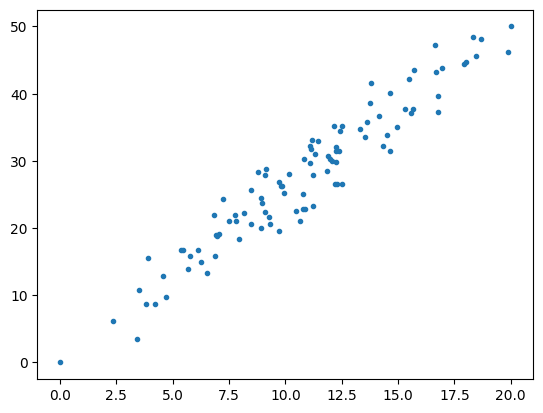

In [3]:
graph_x, data_y, data_x  = get_data(sample_num = 100)

plt.ion() #interactive plot on
plt.plot(graph_x,data_y,'.',label='training data')

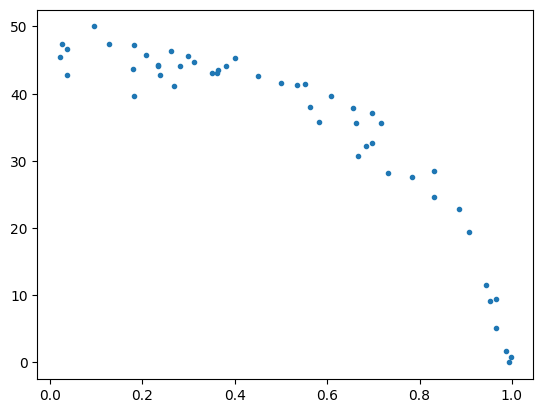

In [4]:
poly_data_x, poly_graph_x, poly_data_y, sample_degree = get_polynomial_data(7)
plt.ion() #interactive plot on
plt.plot(poly_graph_x, poly_data_y,'.',label='training data')

## Modified Gradient descent Method

In [5]:
nums = np.array([0.0, 1.0])

def get_fibonacci_numbers(n):
  global nums
  if n < nums.size:
    return
  for i in range(nums.size - 1, n):
    nums = np.append(nums, nums[i] + nums[i - 1])

def fibonacci_number(n):
  global nums
  if (n < nums.size):
    return nums[n]
  get_fibonacci_numbers(n)
  return nums[n]

#func = lambda x : f(xk - x * Direction) 
def fibonacci_method(func, left_border, right_border, epsilon=0.0001):
  left = left_border
  right = right_border
  n = 0
  lim = (right_border - left_border) / epsilon
  while(fibonacci_number(n) <= lim):
    n += 1
  a = left_border
  b = right_border
  d = right_border - left_border
  for i in range(1, n + 1):
    d = d * (fibonacci_number(n - i)/fibonacci_number(n - i + 1))
    x1 = b - d
    x2 = a + d
    if func(x1) <= func(x2):
      b = x2
    else:
      a = x1
  return (a + b) / 2


In [6]:
def linear_search(condition, step=0.0001):
  lim_right = step
  while lim_right < 100 and condition(lim_right):
    lim_right += step
  return lim_right

def find_step(function, derivate, xk, epsilon=0.001):
  difArray = derivate(xk)
  f = lambda alpha : function(xk - alpha * difArray)
  condition =  lambda alpha : f(0) > f(alpha)
  right_border = linear_search(condition, epsilon)
  return fibonacci_method(f, 0, right_border, epsilon)


In [20]:
class Sgd:
  #static members
  MAX_ITERATIONS = 10000


  def get_function_batches(datax, datay, batch_size=None):
    if (batch_size is None):
      batch_size = datay.size
    ansx = np.array([datax[i : min(i+batch_size, datax.size)] for i in range(0, datax.shape[0], batch_size)], dtype=object)
    ansy = np.array([datay[i : min(i+batch_size, datay.size)] for i in range(0, datay.shape[0], batch_size)], dtype=object)
    return ansx, ansy




  # Setters
  def set_initial_points(self, points):
    if (points is None):
      return
    self.initial_points = points

  def set_epsilon(self, epsilon):
    self.epsilon = epsilon

  def set_step(self, step):
    self.step = step

  def set_scheduler(self, scheduler):
    self.scheduler = scheduler

  def set_function(self, function):
    self.function = function

  def set_derivate(self, derivate):
    self.derivate = derivate
  
  def set_datax(self, datax):
    self.datax = datax
  
  def set_datay(self, datay):
    self.datay = datay

  def set_points(self, points):
    self.points = points

  def set_scheduler(self, scheduler):
    self.scheduler = self.schedulers[scheduler]

  def set_adam(self):
    self.is_adam = True
    self.step = 1
    self.beta1 = 0.9
    self.beta2 = 0.999
    self.grad_sum = 0
    self.sq_grad_sum = 0

  #Constructor

  def __init__(self, n = 2, initial_points=None, epsilon=0.0000001, step = 0.001, scheduler='fib'):
    table = np.array([])
    self.n = n
    if (initial_points is None):
      self.initial_points = np.zeros(n)
    else:
      self.initial_points = initial_points
    self.epsilon = epsilon
    self.step = step
    self.schedulers = {'fib' : self.fib,
                       'exponential' : self.exponential}
    self.is_adam = False
    self.set_scheduler(scheduler)
    self.lambda1 = 0
    self.lambda2 = 0
    




  #Function Generators

  # Getting function Error

  def get_approx(self, beta, xs, ys):
    ans = np.array([])
    for i in xs:
      ans = np.append(ans, beta @ np.transpose(i))
    return ys - ans

  def get_approx_square(self, beta, xs, ys):
    ans = self.get_approx(beta, xs, ys)
    return (1/ys.shape[0]) * ans * ans

  def compute_error(self, beta, datax, datay):
    ans = np.sum(self.get_approx_square(beta, datax, datay))
    ans += (self.lambda1 * np.sum(np.absolute(beta)))
    ans += (self.lambda2 * np.sum(beta ** 2))
    return ans

  def get_error_function(self):
    return lambda datax, datay, beta : self.compute_error(beta, datax, datay)

  # Derivate of Error function by all variables

  def get_relative_error(self, beta, datax, datay, index):
    return np.sum(datax[:, index] * self.get_approx(beta, datax, datay))

  def get_error_devs(self, beta, datax, datay):
    n = datax[0].size
    ans = np.array([])
    m = datay.shape[0]
    for i in range(0, n):
      ans = np.append(ans, (-2/m) * self.get_relative_error(beta, datax, datay, i))
    return ans

  def comp_dev(self, beta, datax, datay):
    ans = self.get_error_devs(beta, datax, datay)
    ans += (2 * self.lambda2 * beta)
    ans += self.lambda1
    return ans

  def get_dev(self):
    return lambda datax, datay, beta : self.comp_dev(beta, datax, datay)





  def fib(self, epoch):
    f = self.function_prot()
    der = self.dev_prot()
    return find_step(f, der, self.points)

  def exponential(self, epoch):
    # print(self.step)
    return self.step / exp(0.1 * epoch)

  def adam(self, grad):
    self.grad_sum = self.grad_sum * self.beta1 + grad * (1 - self.beta1)
    self.sq_grad_sum = self.sq_grad_sum * self.beta2 + ((grad ** 2.0) * (1 - self.beta2))
    vector_sqrt = np.vectorize(sqrt)
    return -1 * (self.step * self.grad_sum) / (vector_sqrt(self.sq_grad_sum + self.epsilon))

  def function_prot(self):
    return lambda points : self.function(self.datax, self.datay, points)
  
  def dev_prot(self):
    return lambda points : self.derivate(self.datax, self.datay, points)

  def compute_dev(self, points):
    return self.derivate(self.datax, self.datay, points)


  
  #Gradient descent function

  def gradient_descent(self, datax, datay):
    iteration = 0
    last_points = ini_points = self.initial_points[:]
    points = last_points[:]
    ans = np.array(points[:])
    dif = np.zeros(points.size);
    while iteration <= self.MAX_ITERATIONS:
      # print(iteration)
      
      # ================Added================ #

      index = iteration % datax.shape[0]
      function = self.get_error_function()
      derivate = self.get_dev()
      self.set_function(function)
      self.set_derivate(derivate)
      self.set_datax(datax[index])
      self.set_datay(datay[index])
      self.set_points(points)

      # ================Added================ #

      # =================Changed================ #
      difArray = self.compute_dev(points)

      if (self.is_adam == False):
        learning_rate = self.scheduler(iteration)
        dif = -1 * learning_rate * difArray
      else:
        dif = self.adam(difArray)
      # =================Changed================ #

      # =================Task3================== #

      # =================Task3================== #

      # points = last_points[:] - difArray
      points = last_points[:] + dif
      ans = np.append(ans, points[:])

      # ===================Changed================= #
      result1 = function(datax[index], datay[index], last_points)
      result2 = function(datax[index], datay[index], points)
      if (lin.norm(difArray) < self.epsilon) or (lin.norm(points - last_points) < self.epsilon) or (abs(result2 - result1) < self.epsilon):
        break
      # ===================Changed================= #

      iteration += 1
      last_points = points[:]
    return ans, iteration, last_points


  def polynomial_regression(self, datax, datay, grade=1):
    self.set_adam()
    newxs = np.ones(datay.shape[0])
    for i in range(1, grade + 1):
      newxs = np.c_[newxs, datax[:, 0]**i]
    self.set_initial_points(np.zeros(grade + 1))
    newxs, newys = Sgd.get_function_batches(newxs, datay)
    return self.gradient_descent(newxs, newys)

  def graph_poly(self, ans, poly_graph_x, poly_data_y):
    print("Polynomial regression found in:", ans[1], "iterations")
    beta = ans[2]
    degree = beta.size - 1
    print("Found values for coefficients: ", beta)
    plt.ion() #interactive plot on
    plt.plot(poly_graph_x, poly_data_y,'.',label='training data')
    # Generate points to plot the polynomial curve
    poly_plot_x = np.linspace(np.min(poly_graph_x), np.max(poly_graph_x), 100)
    poly_plot_X = np.ones((poly_plot_x.shape[0], 1))
    for i in range(1, degree + 1):
        poly_plot_X = np.hstack((poly_plot_X, poly_plot_x.reshape(-1, 1)**i))
    poly_plot_y = poly_plot_X @ beta

    # Plot the polynomial curve and training data
    plt.plot(poly_plot_x, poly_plot_y, '-r', label='polynomial regression')
    plt.xlabel('Input')
    plt.ylabel('Output')
    plt.title('Polynomial Regression')
    plt.legend()
    plt.show()





  #Auxiliar functions for testing

  def test_GD(self, scheduler='fib', full=False):
    self.set_scheduler(scheduler)
    self.table = np.array(['Batch Size', 'found point', 'Iterations taken', 'Converged', 'Time taken'])
    l1 = (1, 10, 30, 50, 99, 100)
    if (full):
      l1 = range(1, 101)
    for i in l1:
      start_time = time.time()
      new_x, new_y = Sgd.get_function_batches(data_x, data_y, i)
      ans = self.gradient_descent(new_x, new_y)
      self.table = np.append(self.table, np.array([i, ans[2], ans[1], ans[1] <= 10000, str(round(time.time() - start_time, 4)) + 's'], dtype=object)) 

  def show_results(self):
    self.table = np.reshape(self.table, ((int)(self.table.size / 5), 5))
    print(tabulate(self.table, headers='firstrow', tablefmt='fancy_grid'))

  def test_poly(self, graphx, datax, datay, full=False):
    lambdas = np.array([0])
    if (full == True):
      lambdas = np.array([0, 0.33, 0.66, 1])
    for i in range(1, 15, 3):
      for j in lambdas:
        self.lambda1 = j
        for k in lambdas:
          self.lambda2 = k
          print("Polynomial regression with grade", i)
          print("Regularization parameters:", j, k)
          ans = self.polynomial_regression(datax, datay, i)
          self.graph_poly(ans, graphx, datay)


#Creating an instance
mySGD = Sgd()
# ans, iteration, last_points = mySGD.polynomial_regression(poly_data_x, poly_data_y, sample_degree)
# print(ans, iteration, last_points)

## Testing Linear regression with Gradient descent (Full batch + fibonacci step)

In [8]:
new_data_x, new_data_y = Sgd.get_function_batches(data_x, data_y)
ans = mySGD.gradient_descent(new_data_x, new_data_y)

### Graphing results

linear regression found in: 112 iterations
Found values for m and c:  [2.44013729 1.25348764]


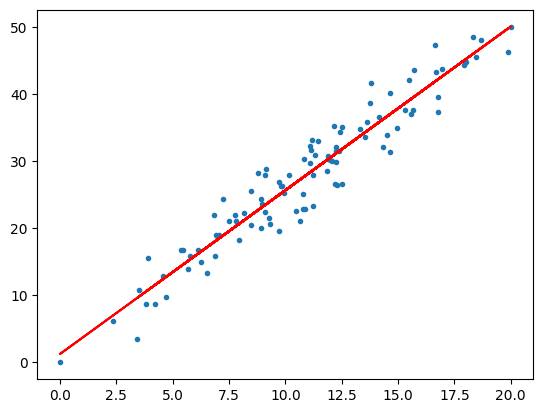

In [9]:
print("linear regression found in:", ans[1], "iterations")
beta = ans[2]
print("Found values for m and c: ", beta)
plt.ion() #interactive plot on
plt.plot(graph_x,data_y,'.',label='training data')
ansy = beta[0] * graph_x + beta[1]
plt.plot(graph_x, ansy, '-r', label='linear regression')

## Polynomial Regression

In [10]:
ans = mySGD.polynomial_regression(poly_data_x, poly_data_y, 11)

### Graphing results

Polynomial regression found in: 7384 iterations
Found values for coefficients:  [ 46.3934754  -11.22457704  26.58290754 -30.00536766 -44.47991607
 -14.54779908  18.07177252  33.21743795  28.67931779   9.53735128
 -17.51872624 -46.44290486]


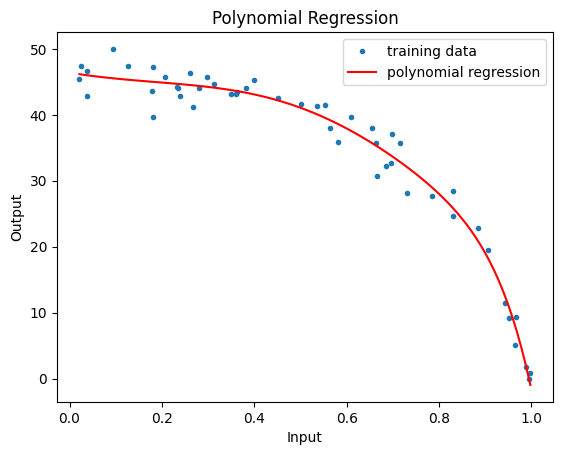

In [11]:
mySGD.graph_poly(ans, poly_graph_x, poly_data_y)

## Polynomial regression with different grades

## Testing Polynomial Regression with different degrees

Polynomial regression with grade 1
Regularization parameters: 0 0
Polynomial regression found in: 187 iterations
Found values for coefficients:  [ 54.99422963 -39.74019627]


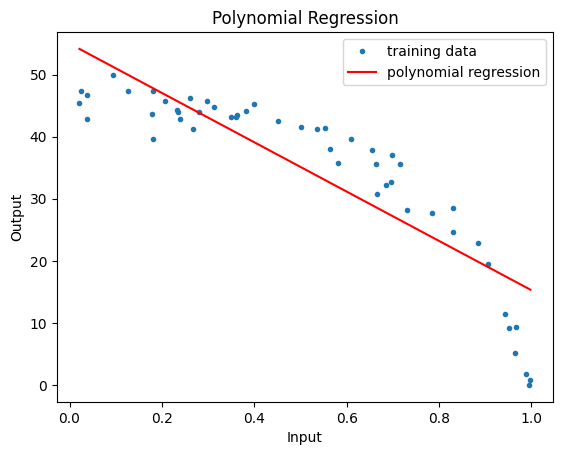

Polynomial regression with grade 4
Regularization parameters: 0 0
Polynomial regression found in: 7574 iterations
Found values for coefficients:  [ 46.56441667  -6.31453393 -22.4791947   70.0142171  -86.64771622]


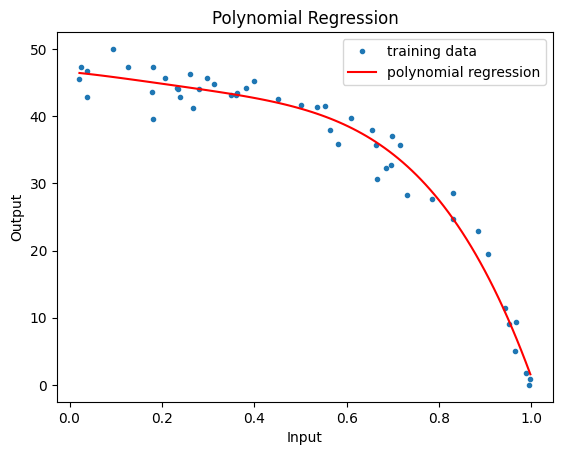

Polynomial regression with grade 7
Regularization parameters: 0 0
Polynomial regression found in: 5298 iterations
Found values for coefficients:  [ 45.75502271   2.05620527 -19.03270169 -22.26051114  10.32322182
  29.73618002   8.74133691 -55.80067858]


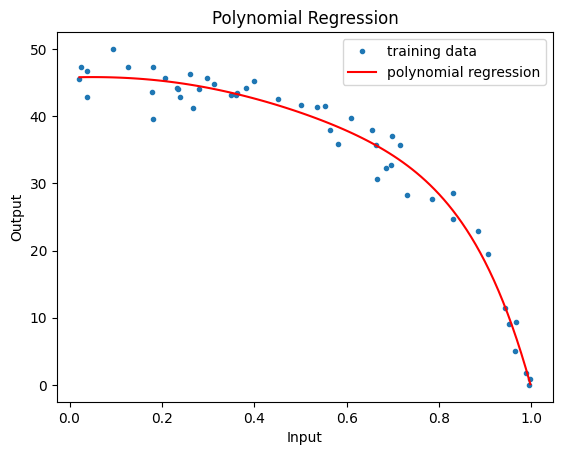

Polynomial regression with grade 10
Regularization parameters: 0 0
Polynomial regression found in: 10855 iterations
Found values for coefficients:  [ 46.53600595 -14.43210539  40.7311241  -42.96938877 -58.63753176
 -11.53667651  35.74560965  52.26670569  33.94373782 -11.25661665
 -72.07888395]


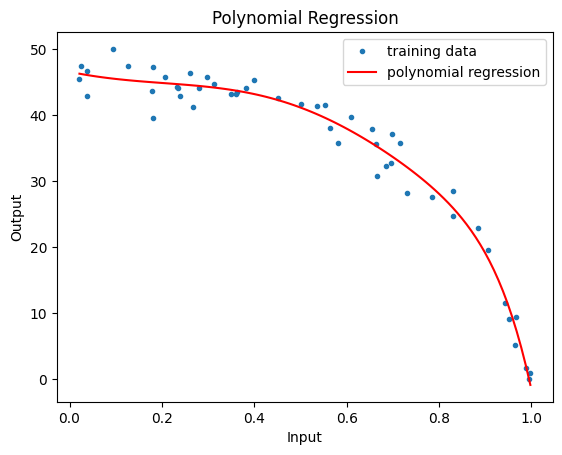

Polynomial regression with grade 13
Regularization parameters: 0 0
Polynomial regression found in: 6624 iterations
Found values for coefficients:  [ 46.34957995  -9.76105374  18.82291871 -21.72498314 -36.0637004
 -16.12930265   8.06176912  20.81841498  20.70278145  11.97354817
  -0.09538261 -10.95782389 -17.22672091 -16.61781043]


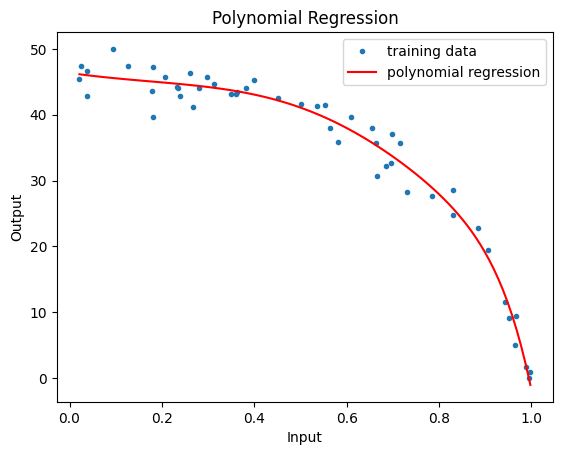

In [12]:
mySGD.test_poly(poly_graph_x, poly_data_x, poly_data_y)

## Regularization

Polynomial regression with grade 1
Regularization parameters: 0.0 0.0
Polynomial regression found in: 187 iterations
Found values for coefficients:  [ 54.99422963 -39.74019627]


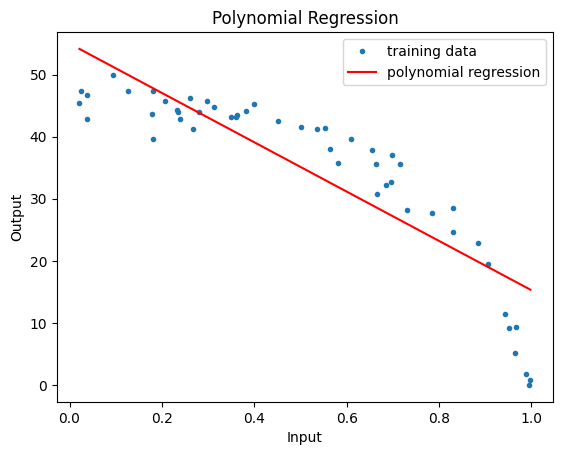

Polynomial regression with grade 1
Regularization parameters: 0.0 0.33
Polynomial regression found in: 185 iterations
Found values for coefficients:  [25.57970048  1.51154565]


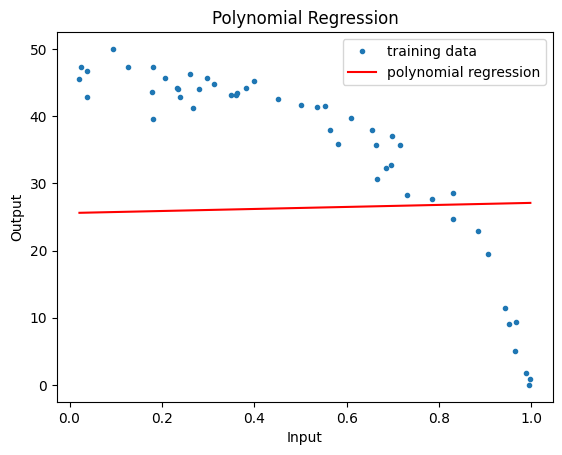

Polynomial regression with grade 1
Regularization parameters: 0.0 0.66
Polynomial regression found in: 171 iterations
Found values for coefficients:  [19.74652767  3.95225969]


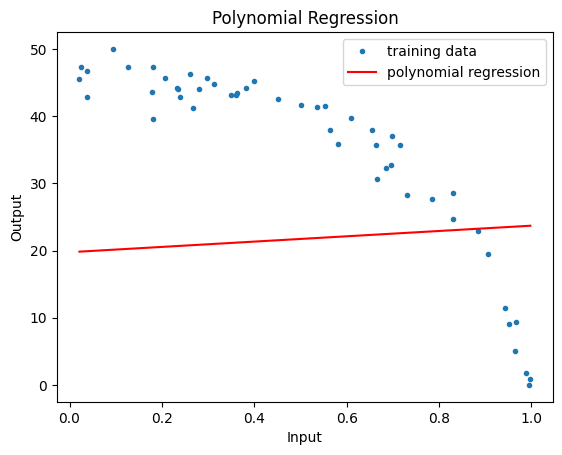

Polynomial regression with grade 1
Regularization parameters: 0.0 1.0
Polynomial regression found in: 164 iterations
Found values for coefficients:  [16.31370398  4.24886319]


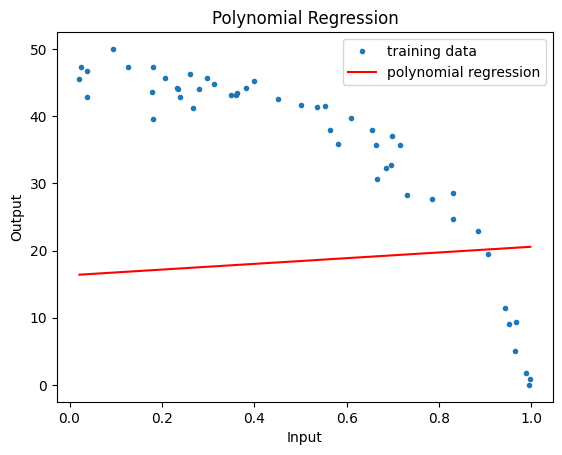

Polynomial regression with grade 1
Regularization parameters: 0.33 0.0
Polynomial regression found in: 273 iterations
Found values for coefficients:  [ 55.27506013 -40.61787539]


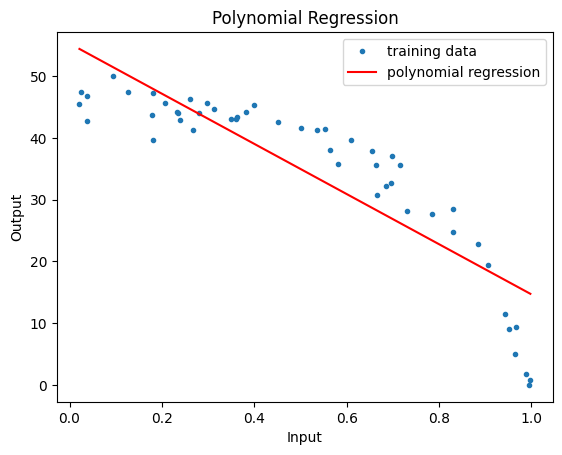

Polynomial regression with grade 1
Regularization parameters: 0.33 0.33
Polynomial regression found in: 174 iterations
Found values for coefficients:  [25.53557223  1.29752304]


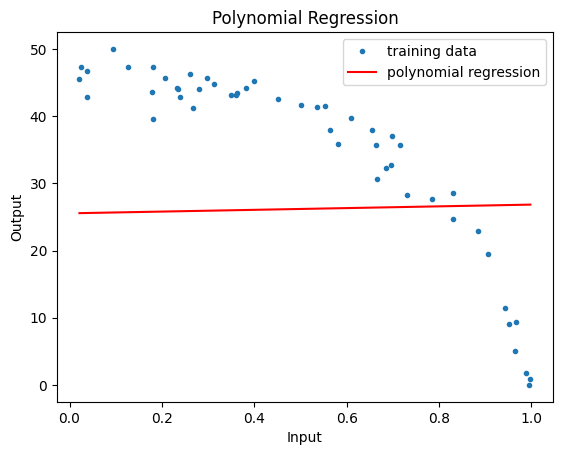

Polynomial regression with grade 1
Regularization parameters: 0.33 0.66
Polynomial regression found in: 180 iterations
Found values for coefficients:  [19.68910042  3.81689456]


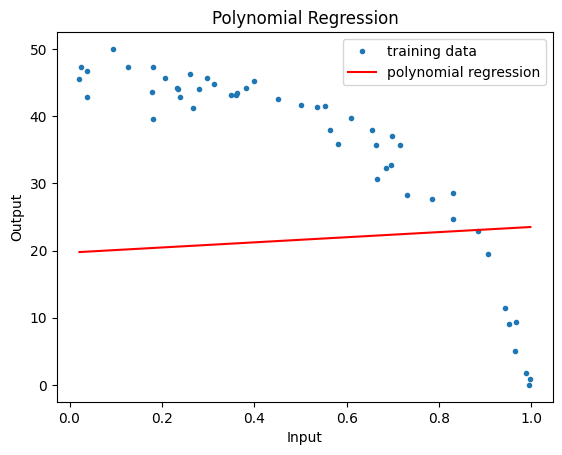

Polynomial regression with grade 1
Regularization parameters: 0.33 1.0
Polynomial regression found in: 180 iterations
Found values for coefficients:  [16.25645332  4.14930912]


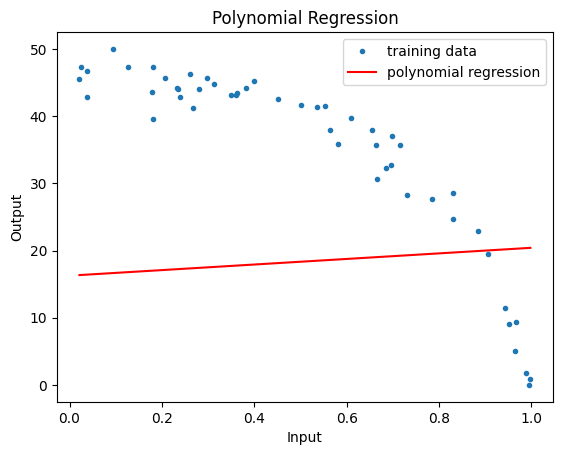

Polynomial regression with grade 1
Regularization parameters: 0.66 0.0
Polynomial regression found in: 217 iterations
Found values for coefficients:  [ 55.55852042 -41.49968591]


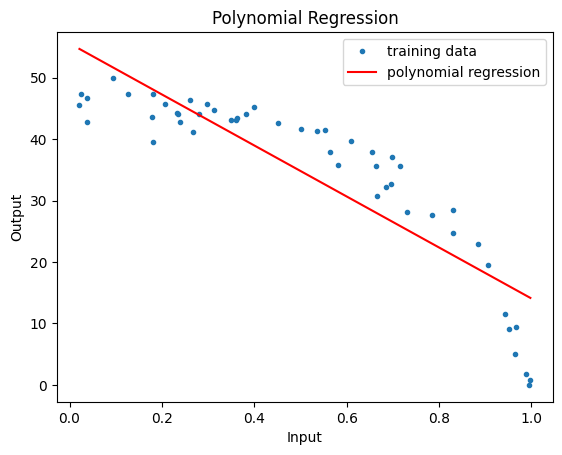

Polynomial regression with grade 1
Regularization parameters: 0.66 0.33
Polynomial regression found in: 179 iterations
Found values for coefficients:  [25.49137938  1.09058251]


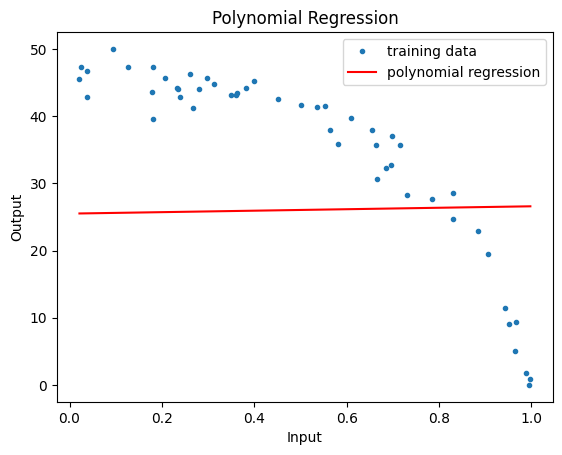

Polynomial regression with grade 1
Regularization parameters: 0.66 0.66
Polynomial regression found in: 174 iterations
Found values for coefficients:  [19.62975699  3.68176545]


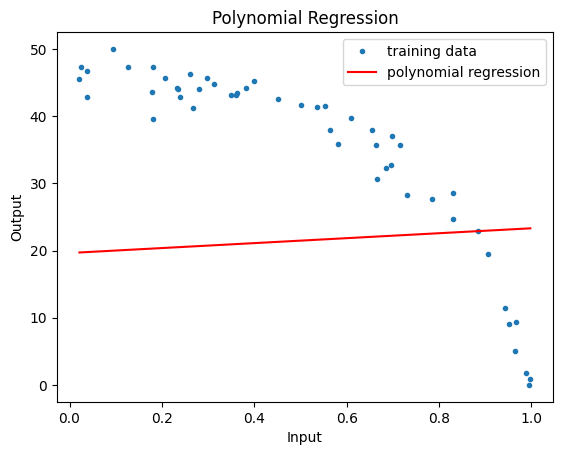

Polynomial regression with grade 1
Regularization parameters: 0.66 1.0
Polynomial regression found in: 176 iterations
Found values for coefficients:  [16.19922941  4.04758454]


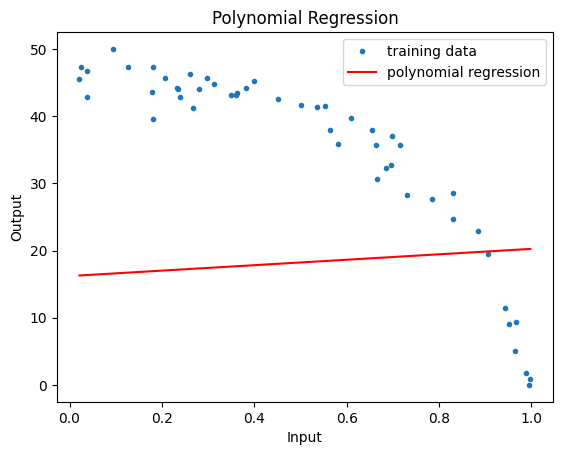

Polynomial regression with grade 1
Regularization parameters: 1.0 0.0
Polynomial regression found in: 273 iterations
Found values for coefficients:  [ 55.85038777 -42.40831384]


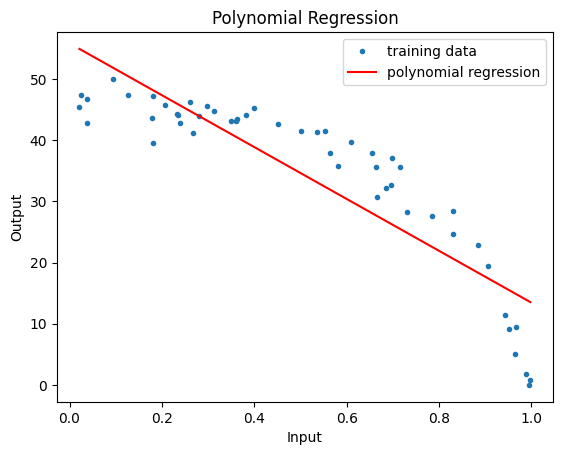

Polynomial regression with grade 1
Regularization parameters: 1.0 0.33
Polynomial regression found in: 183 iterations
Found values for coefficients:  [25.44660537  0.87640161]


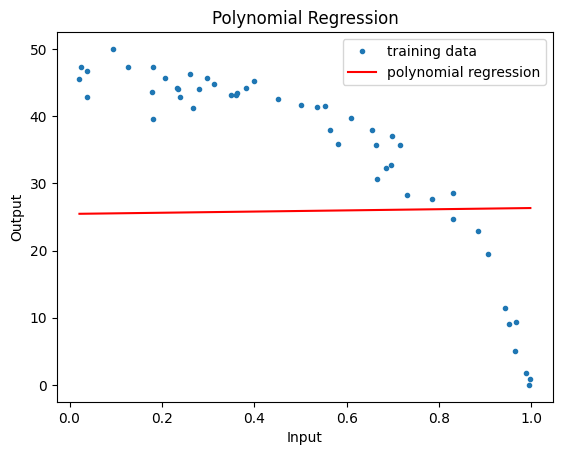

Polynomial regression with grade 1
Regularization parameters: 1.0 0.66
Polynomial regression found in: 179 iterations
Found values for coefficients:  [19.57066585  3.54510667]


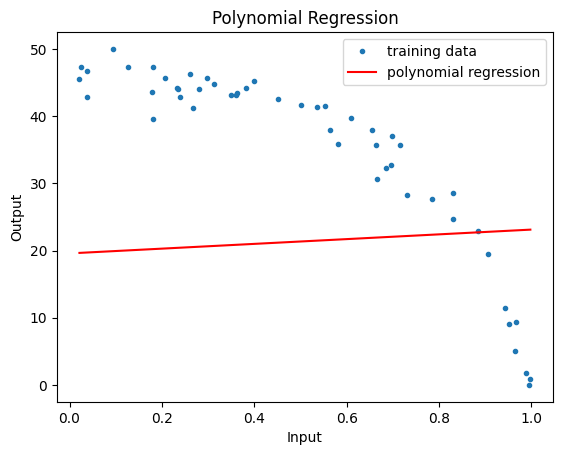

Polynomial regression with grade 1
Regularization parameters: 1.0 1.0
Polynomial regression found in: 175 iterations
Found values for coefficients:  [16.14063236  3.94366773]


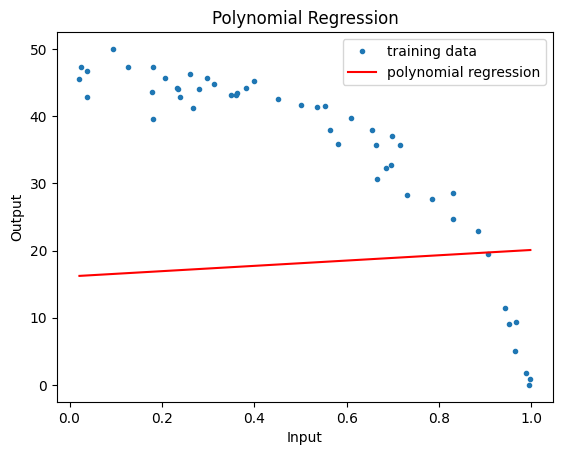

Polynomial regression with grade 4
Regularization parameters: 0.0 0.0
Polynomial regression found in: 7574 iterations
Found values for coefficients:  [ 46.56441667  -6.31453393 -22.4791947   70.0142171  -86.64771622]


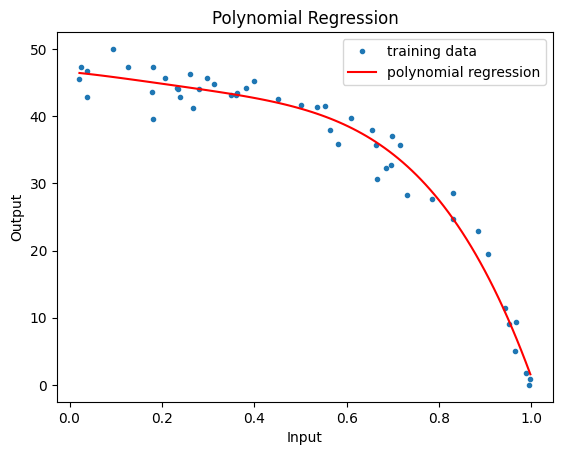

Polynomial regression with grade 4
Regularization parameters: 0.0 0.33
Polynomial regression found in: 179 iterations
Found values for coefficients:  [26.64335127  4.05375026 -1.66456158 -3.79102081 -4.72254148]


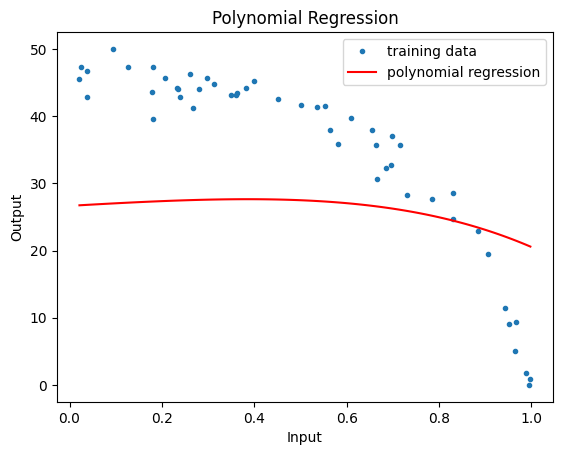

Polynomial regression with grade 4
Regularization parameters: 0.0 0.66
Polynomial regression found in: 159 iterations
Found values for coefficients:  [20.01871095  4.39562873  0.32583516 -1.24030647 -1.96285223]


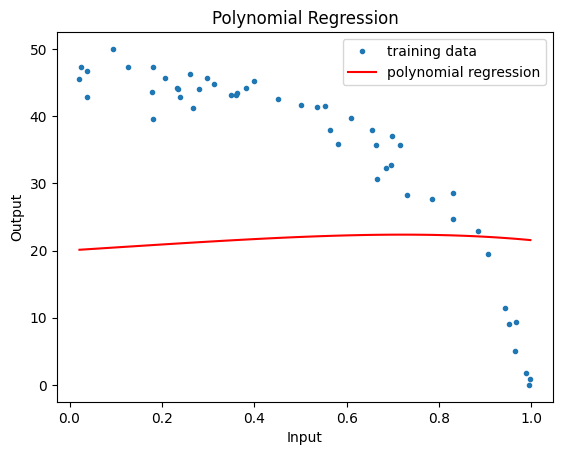

Polynomial regression with grade 4
Regularization parameters: 0.0 1.0
Polynomial regression found in: 177 iterations
Found values for coefficients:  [16.27365682  4.2255964   1.02071164 -0.24946686 -0.8567026 ]


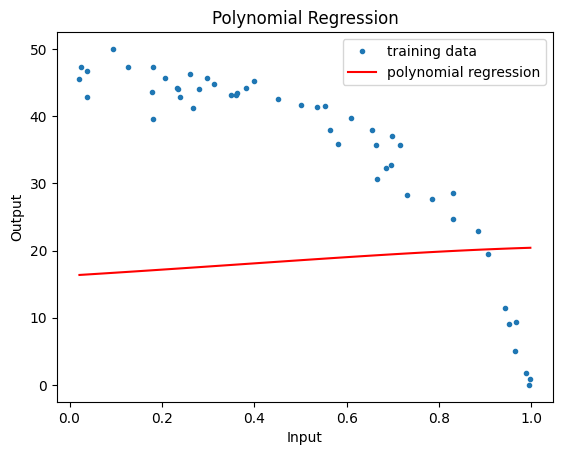

Polynomial regression with grade 4
Regularization parameters: 0.33 0.0
Polynomial regression found in: 10001 iterations
Found values for coefficients:  [  46.25213437    2.71258901  -73.38303131  162.79309487 -139.247822  ]


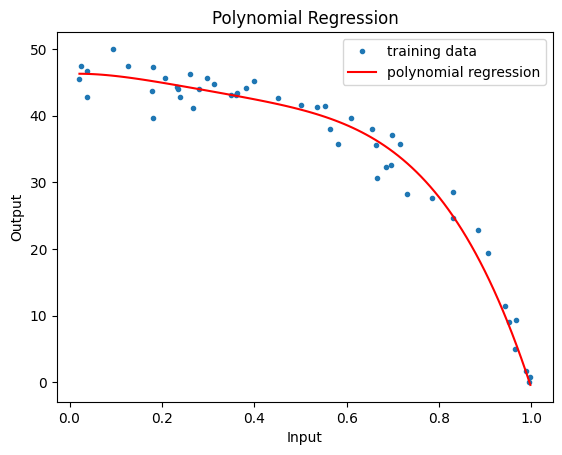

Polynomial regression with grade 4
Regularization parameters: 0.33 0.33
Polynomial regression found in: 260 iterations
Found values for coefficients:  [26.65579794  3.97668408 -1.80025271 -3.96685591 -4.92766581]


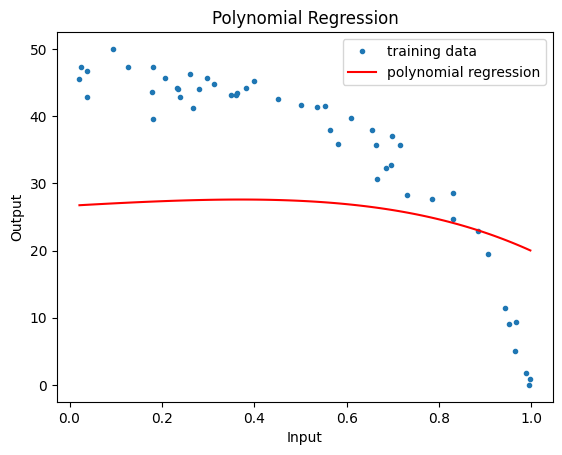

Polynomial regression with grade 4
Regularization parameters: 0.33 0.66
Polynomial regression found in: 263 iterations
Found values for coefficients:  [20.00051584  4.32403728  0.22634612 -1.36107222 -2.09817895]


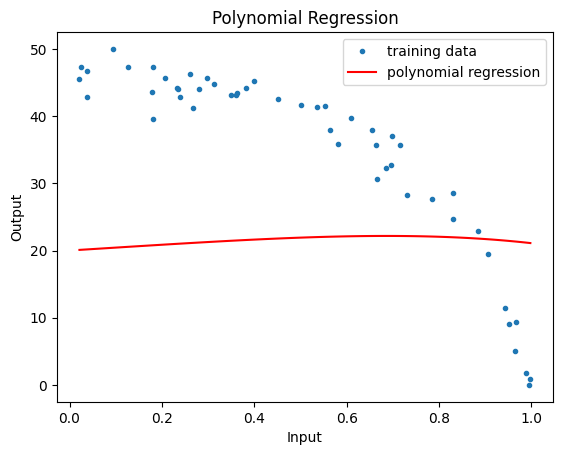

Polynomial regression with grade 4
Regularization parameters: 0.33 1.0
Polynomial regression found in: 301 iterations
Found values for coefficients:  [16.24623094  4.16205306  0.93796831 -0.34273957 -0.95702858]


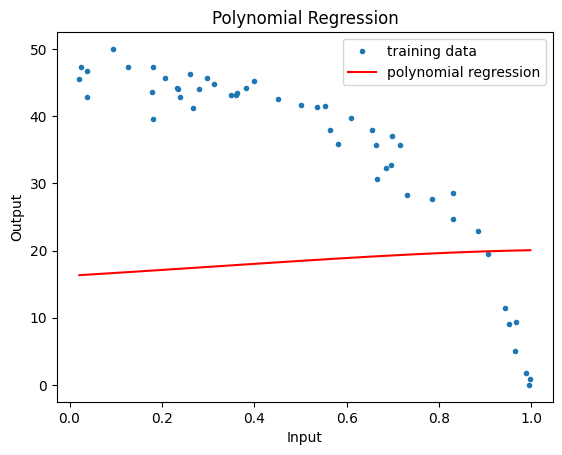

Polynomial regression with grade 4
Regularization parameters: 0.66 0.0
Polynomial regression found in: 10001 iterations
Found values for coefficients:  [  46.21384825    6.58668633 -100.79715105  219.39296744 -174.03081292]


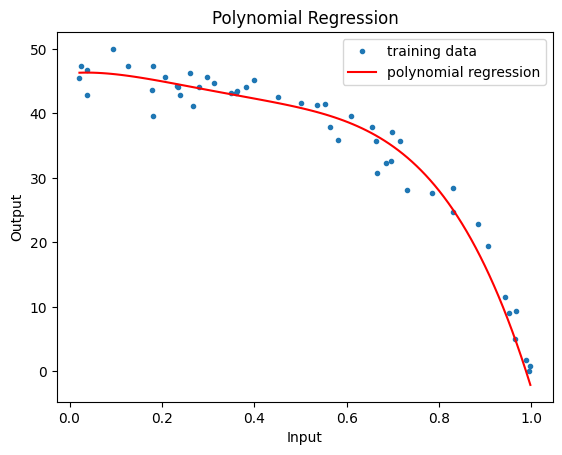

Polynomial regression with grade 4
Regularization parameters: 0.66 0.33
Polynomial regression found in: 259 iterations
Found values for coefficients:  [26.66923352  3.89932612 -1.93634733 -4.14350125 -5.13406031]


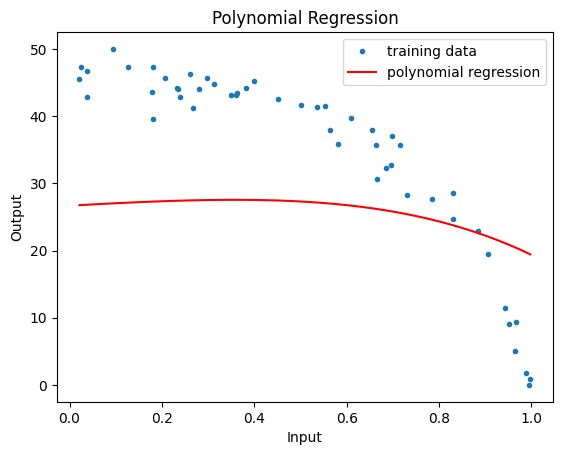

Polynomial regression with grade 4
Regularization parameters: 0.66 0.66
Polynomial regression found in: 295 iterations
Found values for coefficients:  [19.98351628  4.25093183  0.12417434 -1.48173027 -2.23183526]


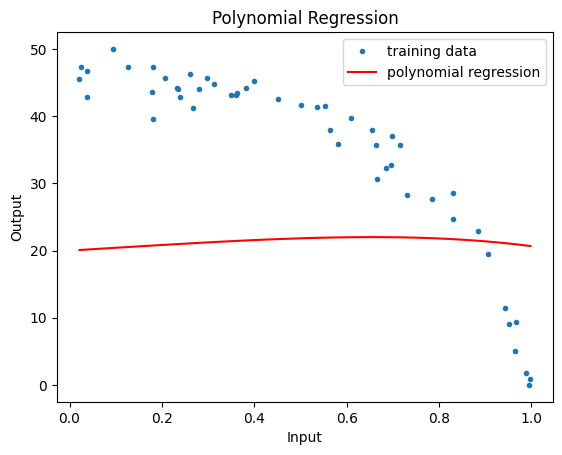

Polynomial regression with grade 4
Regularization parameters: 0.66 1.0
Polynomial regression found in: 297 iterations
Found values for coefficients:  [16.21883667  4.09762609  0.85577861 -0.435847   -1.05766893]


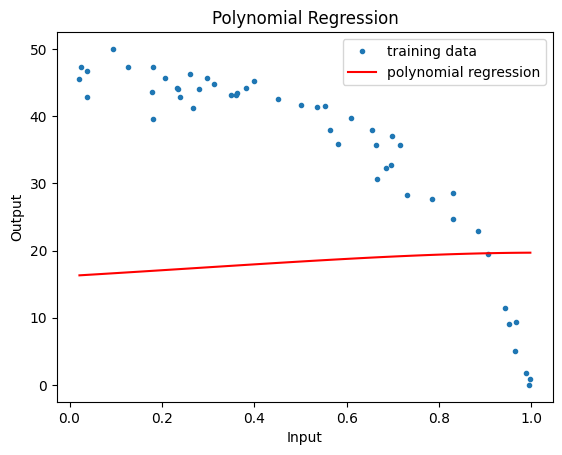

Polynomial regression with grade 4
Regularization parameters: 1.0 0.0
Polynomial regression found in: 10001 iterations
Found values for coefficients:  [  46.13625507   10.59971203 -129.33435313  278.06712685 -210.09660626]


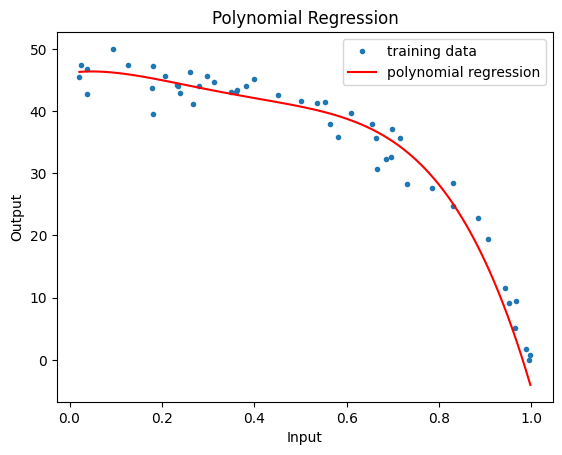

Polynomial regression with grade 4
Regularization parameters: 1.0 0.33
Polynomial regression found in: 316 iterations
Found values for coefficients:  [26.68308286  3.81966724 -2.07657363 -4.3255147  -5.34672593]


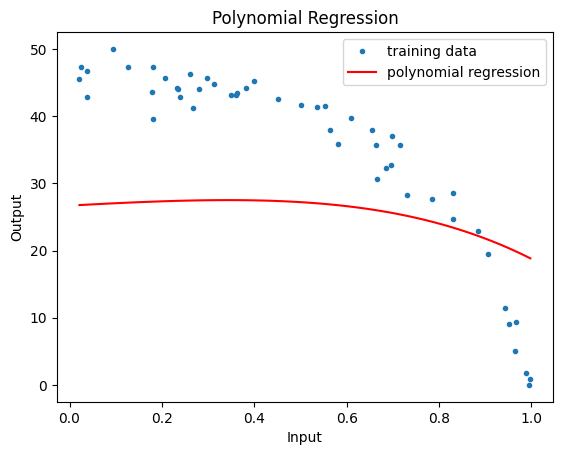

Polynomial regression with grade 4
Regularization parameters: 1.0 0.66
Polynomial regression found in: 292 iterations
Found values for coefficients:  [ 1.99659921e+01  4.17560626e+00  1.89076015e-02 -1.60603952e+00
 -2.36953554e+00]


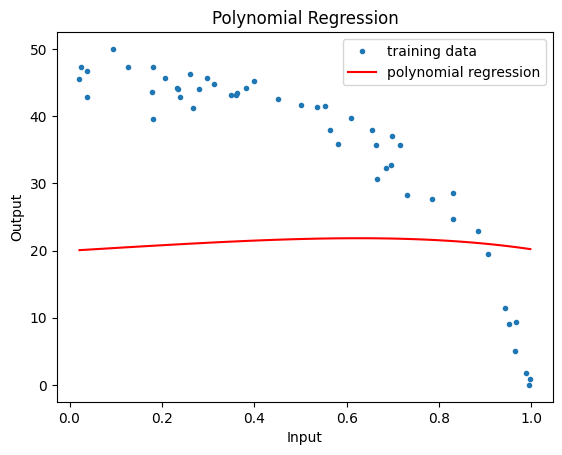

Polynomial regression with grade 4
Regularization parameters: 1.0 1.0
Polynomial regression found in: 306 iterations
Found values for coefficients:  [16.1906141   4.03124647  0.77109777 -0.5317755  -1.16135869]


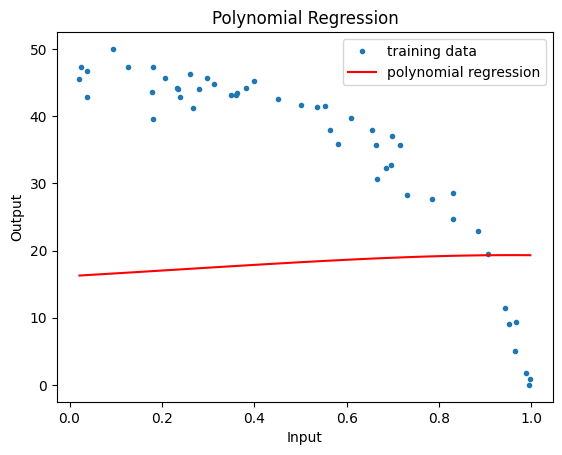

Polynomial regression with grade 7
Regularization parameters: 0.0 0.0
Polynomial regression found in: 5298 iterations
Found values for coefficients:  [ 45.75502271   2.05620527 -19.03270169 -22.26051114  10.32322182
  29.73618002   8.74133691 -55.80067858]


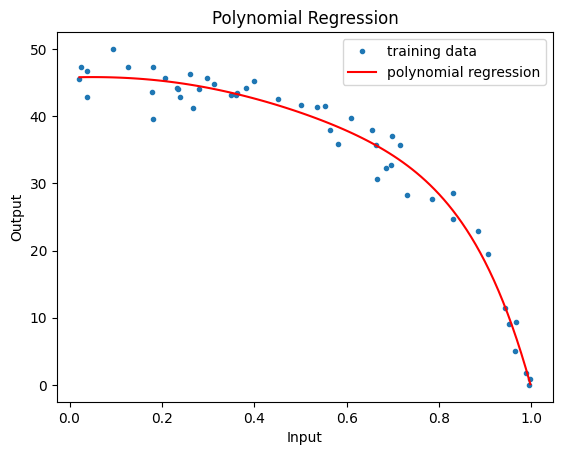

Polynomial regression with grade 7
Regularization parameters: 0.0 0.33
Polynomial regression found in: 165 iterations
Found values for coefficients:  [26.81705451  5.1067981  -0.28719529 -2.27450481 -3.15131257 -3.57384595
 -3.78119823 -3.87515124]


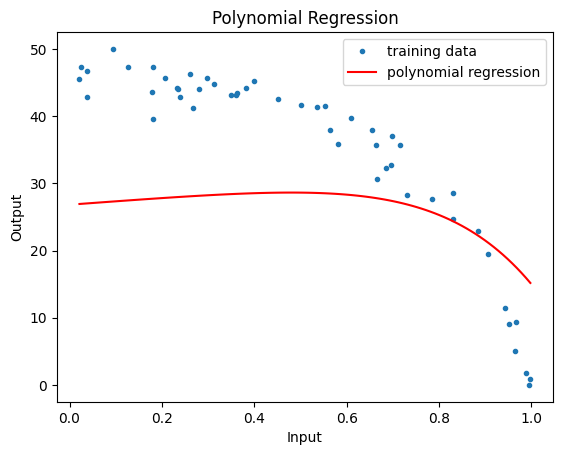

Polynomial regression with grade 7
Regularization parameters: 0.0 0.66
Polynomial regression found in: 184 iterations
Found values for coefficients:  [20.22903727  4.85747351  0.86232108 -0.68404251 -1.40472222 -1.77874414
 -1.98259566 -2.09379831]


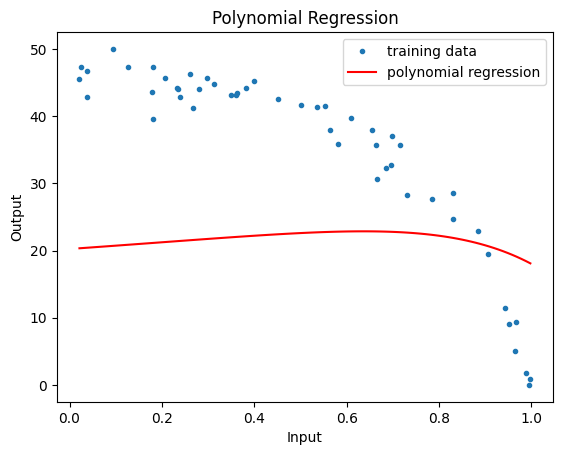

Polynomial regression with grade 7
Regularization parameters: 0.0 1.0
Polynomial regression found in: 179 iterations
Found values for coefficients:  [ 1.64093377e+01  4.44768935e+00  1.26253702e+00 -2.92821788e-03
 -6.12273921e-01 -9.40054175e-01 -1.12824645e+00 -1.23865777e+00]


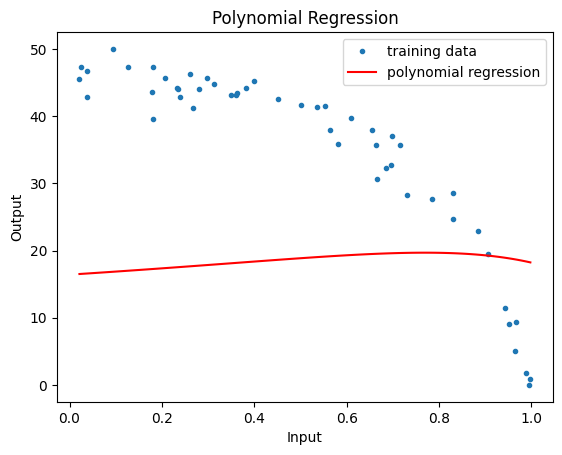

Polynomial regression with grade 7
Regularization parameters: 0.33 0.0
Polynomial regression found in: 10001 iterations
Found values for coefficients:  [  45.75810637   -1.0279091     8.64334758  -79.12715809   -1.50003239
   93.76842967   67.4424764  -137.25528018]


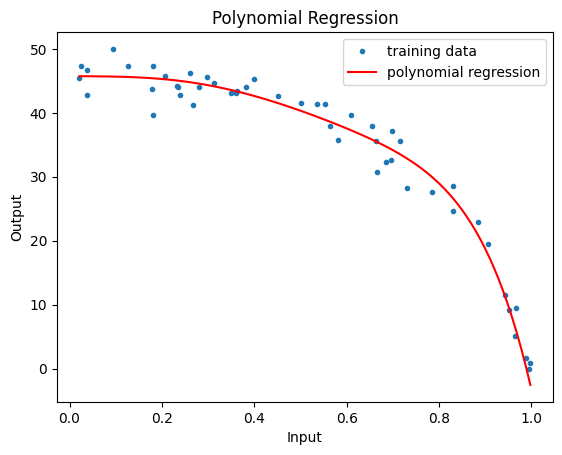

Polynomial regression with grade 7
Regularization parameters: 0.33 0.33
Polynomial regression found in: 295 iterations
Found values for coefficients:  [26.83864931  5.07759962 -0.36091461 -2.383674   -3.28533265 -3.72842964
 -3.95334363 -4.0627516 ]


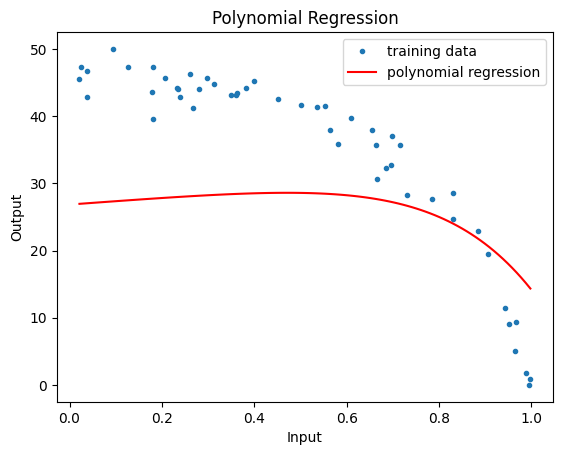

Polynomial regression with grade 7
Regularization parameters: 0.33 0.66
Polynomial regression found in: 287 iterations
Found values for coefficients:  [20.22467285  4.81311324  0.79239677 -0.77117035 -1.50493697 -1.88873962
 -2.10070816 -2.21888666]


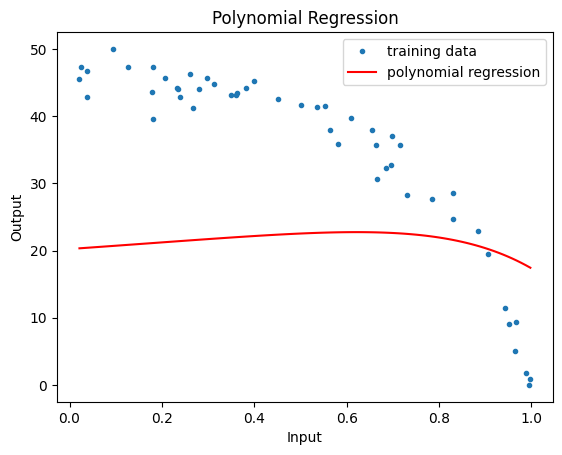

Polynomial regression with grade 7
Regularization parameters: 0.33 1.0
Polynomial regression found in: 267 iterations
Found values for coefficients:  [16.39322781  4.40206546  1.20059091 -0.0759462  -0.69266447 -1.02656471
 -1.21928073 -1.3336561 ]


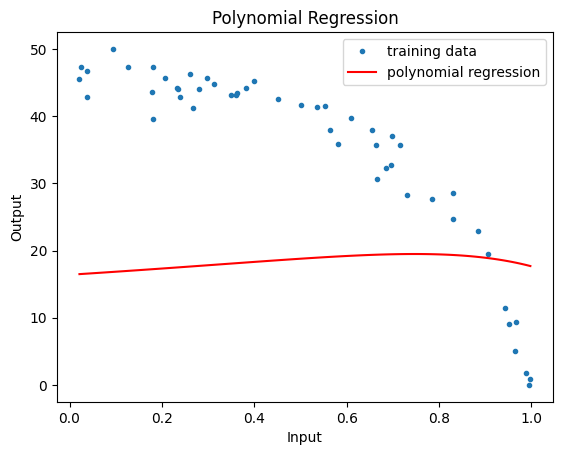

Polynomial regression with grade 7
Regularization parameters: 0.66 0.0
Polynomial regression found in: 10001 iterations
Found values for coefficients:  [  45.56409606    1.04887613   10.60073952 -103.51789644    3.07129352
  130.29836729   93.71224425 -186.73411931]


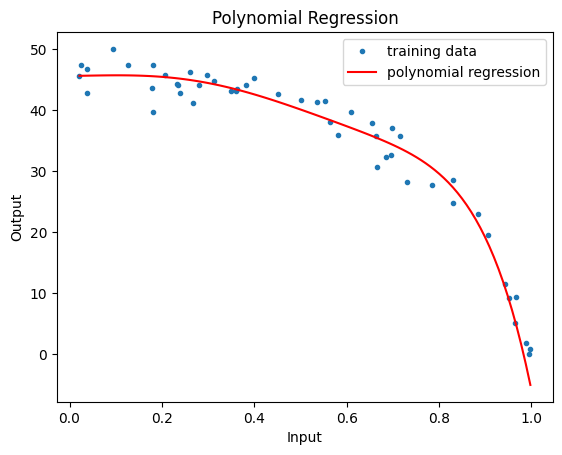

Polynomial regression with grade 7
Regularization parameters: 0.66 0.33
Polynomial regression found in: 322 iterations
Found values for coefficients:  [26.86005831  5.04879207 -0.43344762 -2.49034904 -3.41910501 -3.88425159
 -4.12753941 -4.25258243]


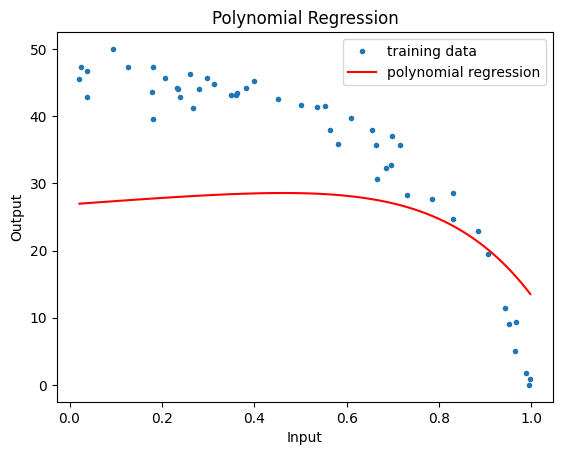

Polynomial regression with grade 7
Regularization parameters: 0.66 0.66
Polynomial regression found in: 263 iterations
Found values for coefficients:  [20.22042427  4.76784967  0.72244356 -0.8582569  -1.60484557 -1.99869697
 -2.2188362  -2.34383169]


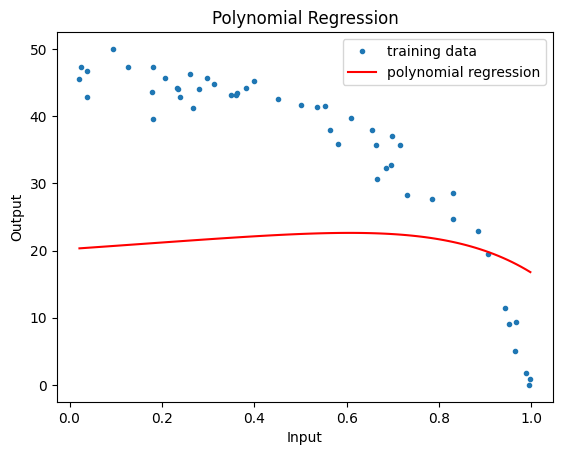

Polynomial regression with grade 7
Regularization parameters: 0.66 1.0
Polynomial regression found in: 269 iterations
Found values for coefficients:  [16.37712888  4.35600924  1.13849032 -0.14866904 -0.77311902 -1.11298579
 -1.31048013 -1.42882009]


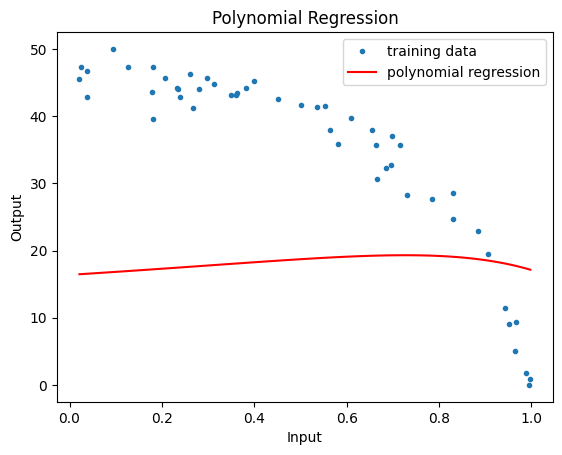

Polynomial regression with grade 7
Regularization parameters: 1.0 0.0
Polynomial regression found in: 10001 iterations
Found values for coefficients:  [  45.36764657    3.10795301   13.02875923 -129.25841547    7.76832046
  168.30546629  121.00741783 -238.02250344]


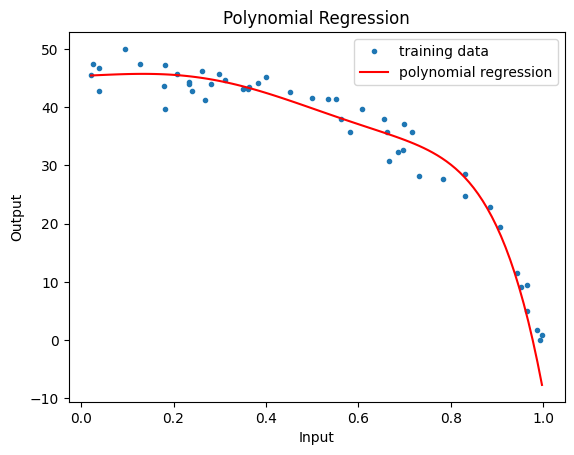

Polynomial regression with grade 7
Regularization parameters: 1.0 0.33
Polynomial regression found in: 324 iterations
Found values for coefficients:  [26.8821194   5.01911079 -0.50817709 -2.60025822 -3.55693163 -4.04479518
 -4.30701443 -4.44816485]


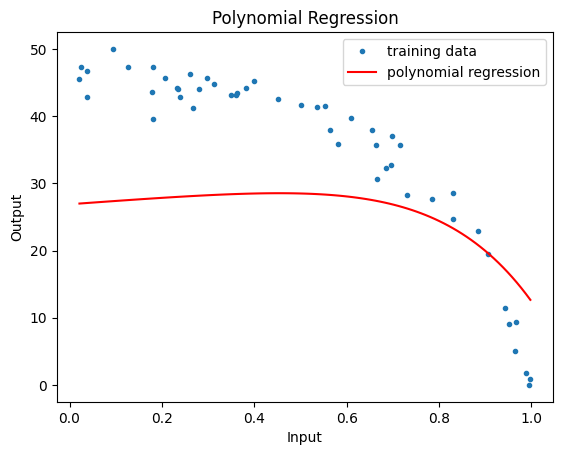

Polynomial regression with grade 7
Regularization parameters: 1.0 0.66
Polynomial regression found in: 275 iterations
Found values for coefficients:  [20.21607084  4.72118247  0.65036349 -0.94799108 -1.70777172 -2.1119835
 -2.34053446 -2.472557  ]


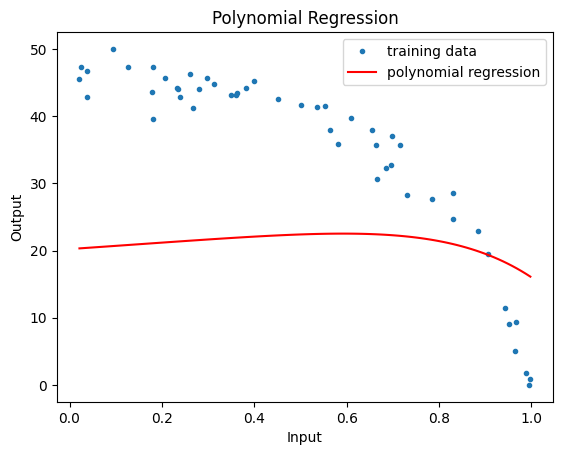

Polynomial regression with grade 7
Regularization parameters: 1.0 1.0
Polynomial regression found in: 290 iterations
Found values for coefficients:  [16.36054079  4.30857189  1.07450125 -0.22359326 -0.856008   -1.20201874
 -1.40444807 -1.52686555]


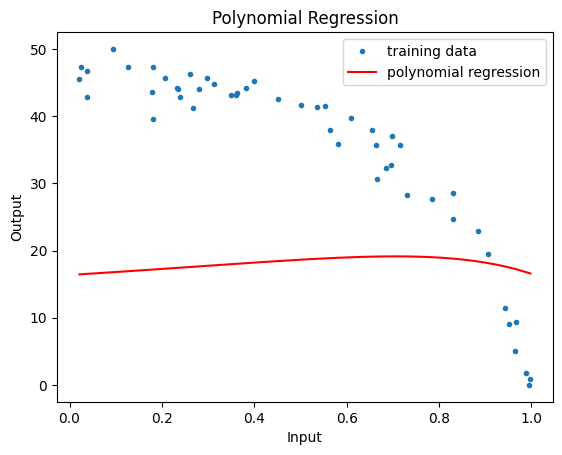

Polynomial regression with grade 10
Regularization parameters: 0.0 0.0
Polynomial regression found in: 10001 iterations
Found values for coefficients:  [ 46.49396603 -13.67506593  38.09231915 -41.83856271 -55.91333297
 -10.63307247  34.33496454  49.9071187   32.30959131 -11.03961271
 -69.71484956]


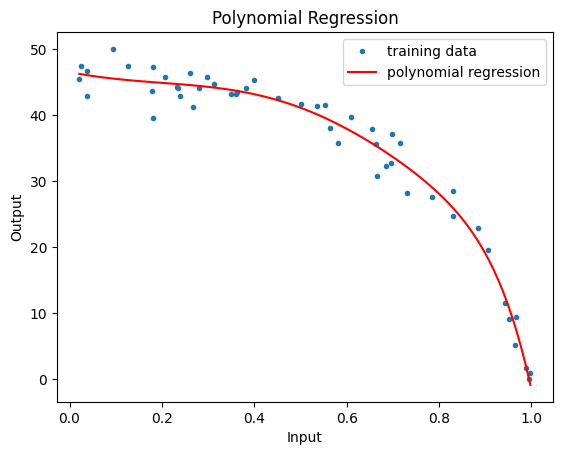

Polynomial regression with grade 10
Regularization parameters: 0.0 0.33
Polynomial regression found in: 174 iterations
Found values for coefficients:  [26.81867265  5.52445608  0.34277531 -1.53556418 -2.34619141 -2.72952122
 -2.91770929 -3.00357536 -3.03270344 -3.02911753 -3.00614864]


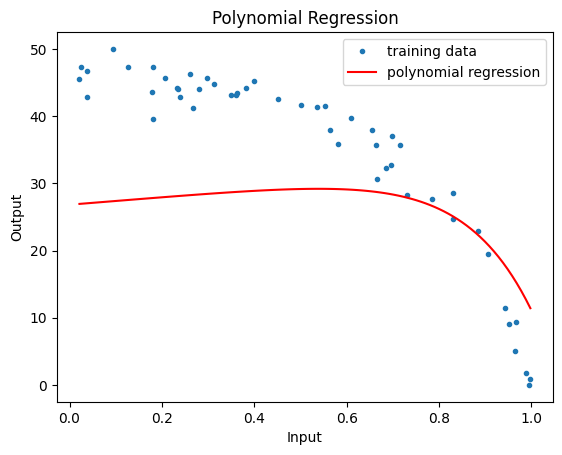

Polynomial regression with grade 10
Regularization parameters: 0.0 0.66
Polynomial regression found in: 175 iterations
Found values for coefficients:  [20.31888062  5.11343321  1.18137597 -0.33519827 -1.04168101 -1.40984947
 -1.61254631 -1.72584479 -1.78717052 -1.81661744 -1.82592481]


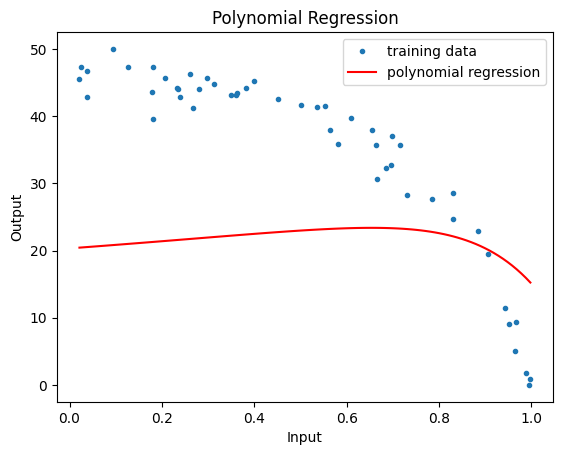

Polynomial regression with grade 10
Regularization parameters: 0.0 1.0
Polynomial regression found in: 181 iterations
Found values for coefficients:  [16.48863011  4.59760155  1.43713719  0.18079888 -0.42416518 -0.75170209
 -0.94101915 -1.05388416 -1.12107869 -1.15988747 -1.18049404]


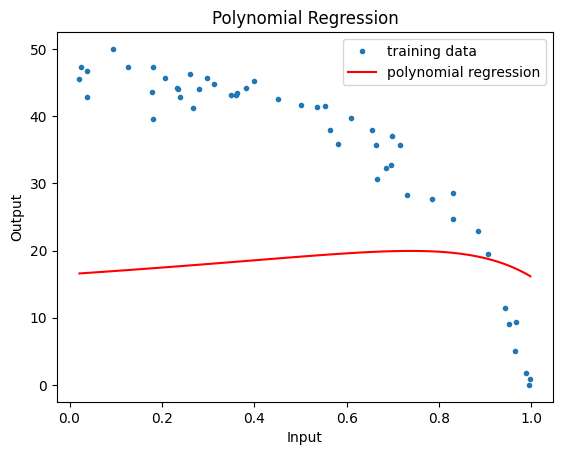

Polynomial regression with grade 10
Regularization parameters: 0.33 0.0
Polynomial regression found in: 10001 iterations
Found values for coefficients:  [  46.71821146  -19.02614983   61.57270673  -55.48431912  -85.37287585
  -22.43609015   51.57798455   87.59479888   68.38983923   -6.73076888
 -131.57584555]


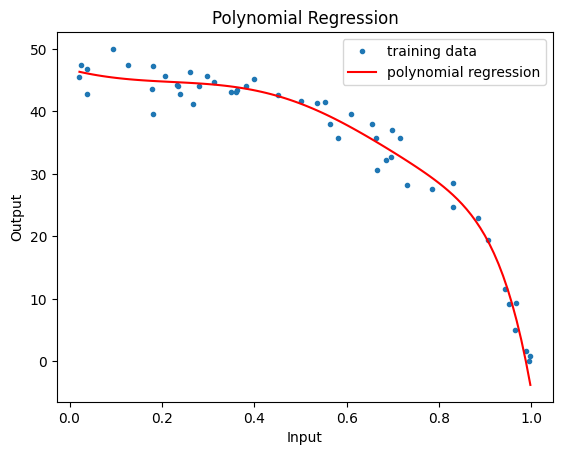

Polynomial regression with grade 10
Regularization parameters: 0.33 0.33
Polynomial regression found in: 294 iterations
Found values for coefficients:  [26.83914791  5.52117418  0.30166494 -1.60102027 -2.43434318 -2.83901039
 -3.04383575 -3.14481612 -3.18768591 -3.19644764 -3.18461312]


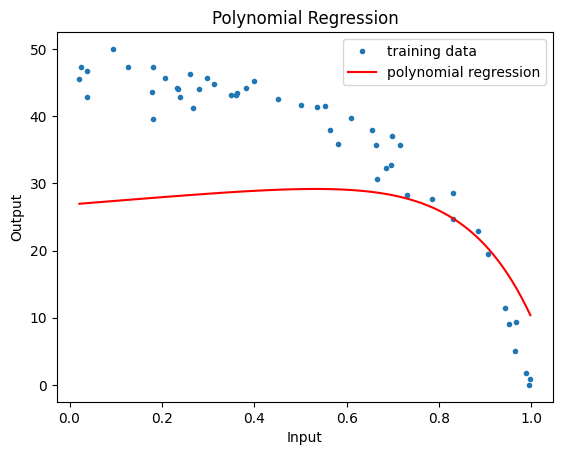

Polynomial regression with grade 10
Regularization parameters: 0.33 0.66
Polynomial regression found in: 246 iterations
Found values for coefficients:  [20.32070251  5.0842677   1.13170885 -0.40018054 -1.11904395 -1.49683024
 -1.70787421 -1.82819105 -1.89541441 -1.93005448 -1.94406673]


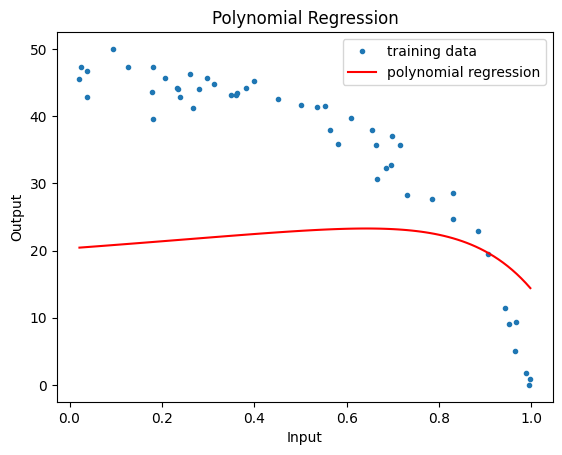

Polynomial regression with grade 10
Regularization parameters: 0.33 1.0
Polynomial regression found in: 245 iterations
Found values for coefficients:  [16.47871315  4.56348745  1.38818716  0.12226137 -0.49059984 -0.82404476
 -1.01817081 -1.13501422 -1.20580607 -1.24782705 -1.27126883]


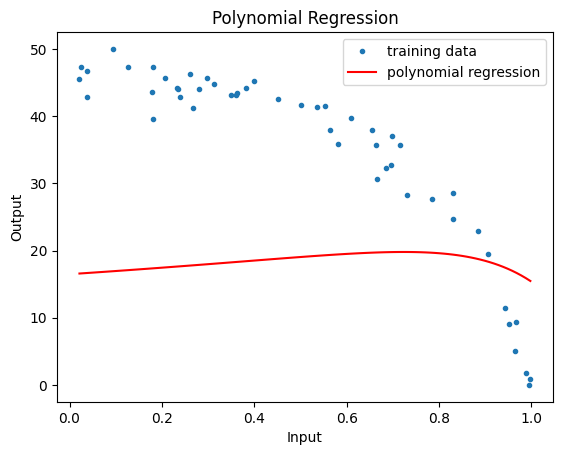

Polynomial regression with grade 10
Regularization parameters: 0.66 0.0
Polynomial regression found in: 10001 iterations
Found values for coefficients:  [  46.89066779  -24.50710374   85.26362922  -69.30029933 -115.26030644
  -34.24948969   69.00021255  125.39984674  104.44600754   -2.56717043
 -193.60049129]


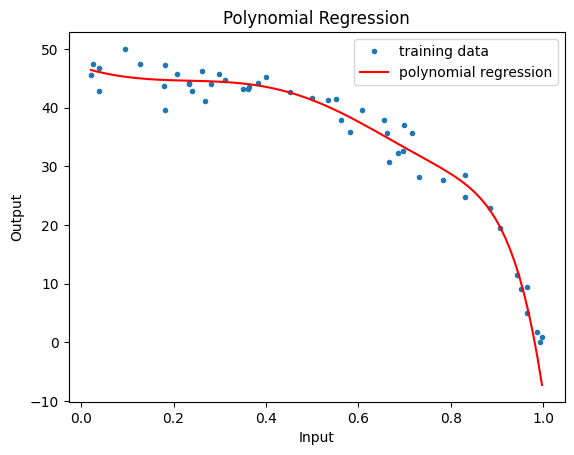

Polynomial regression with grade 10
Regularization parameters: 0.66 0.33
Polynomial regression found in: 294 iterations
Found values for coefficients:  [26.86054183  5.51549184  0.26372891 -1.66679768 -2.52362483 -2.9483141
 -3.17044763 -3.28660941 -3.34296722 -3.36384463 -3.36299594]


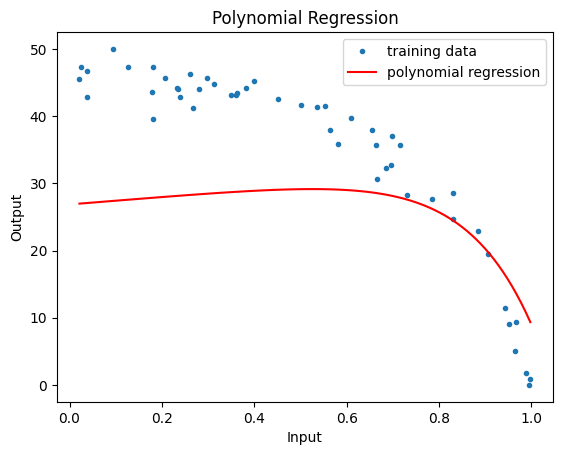

Polynomial regression with grade 10
Regularization parameters: 0.66 0.66
Polynomial regression found in: 304 iterations
Found values for coefficients:  [20.3221142   5.05495083  1.08167104 -0.46547775 -1.19625871 -1.58373317
 -1.80289278 -1.93014249 -2.00341414 -2.04341275 -2.06222556]


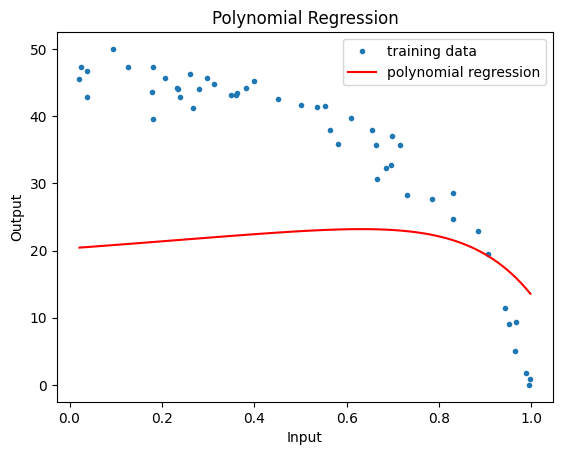

Polynomial regression with grade 10
Regularization parameters: 0.66 1.0
Polynomial regression found in: 284 iterations
Found values for coefficients:  [16.46867937  4.52883996  1.3393177   0.06352849 -0.55678552 -0.89616504
 -1.09517177 -1.21614386 -1.29051119 -1.33566755 -1.36189947]


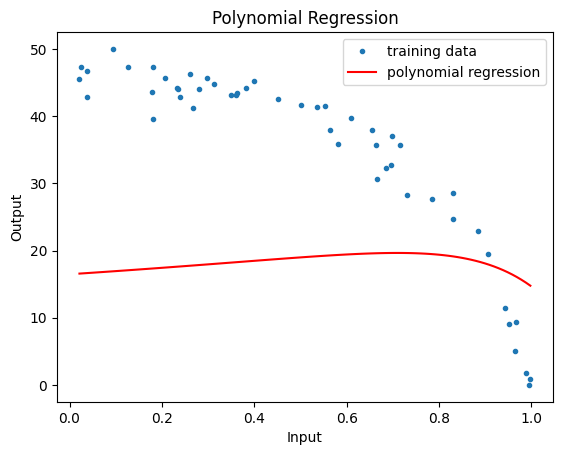

Polynomial regression with grade 10
Regularization parameters: 1.0 0.0
Polynomial regression found in: 10001 iterations
Found values for coefficients:  [  47.10105576  -30.21421446  110.01812311  -83.6540543  -146.42720232
  -46.3586802    87.21253154  164.58160545  141.70658042    1.68356128
 -257.65105404]


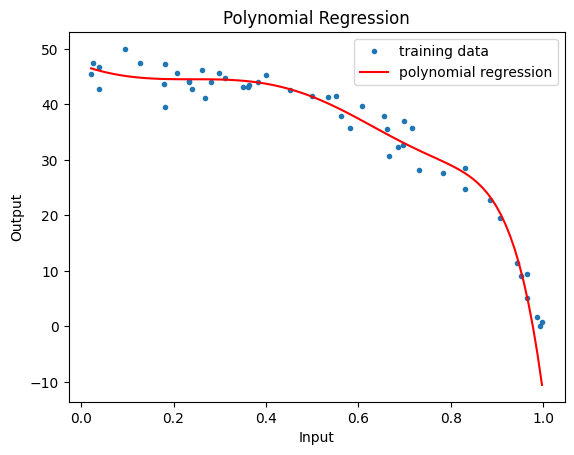

Polynomial regression with grade 10
Regularization parameters: 1.0 0.33
Polynomial regression found in: 263 iterations
Found values for coefficients:  [26.88258139  5.5096221   0.22462902 -1.73455938 -2.61561096 -3.06092569
 -3.30089037 -3.43269193 -3.50295142 -3.53631392 -3.54678331]


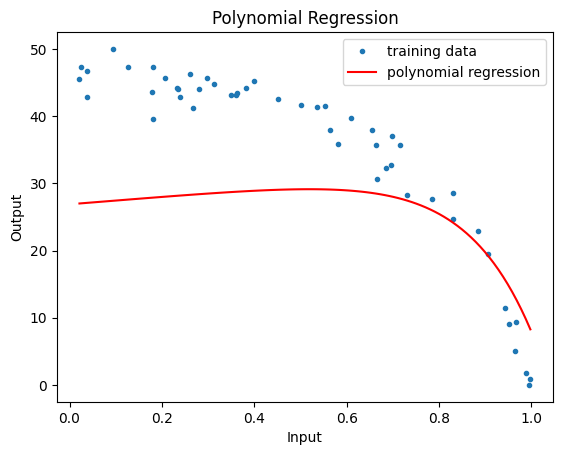

Polynomial regression with grade 10
Regularization parameters: 1.0 0.66
Polynomial regression found in: 315 iterations
Found values for coefficients:  [20.32355225  5.02472502  1.0301394  -0.53273587 -1.27580971 -1.67327297
 -1.90078888 -2.03518974 -2.11469574 -2.16021115 -2.18396664]


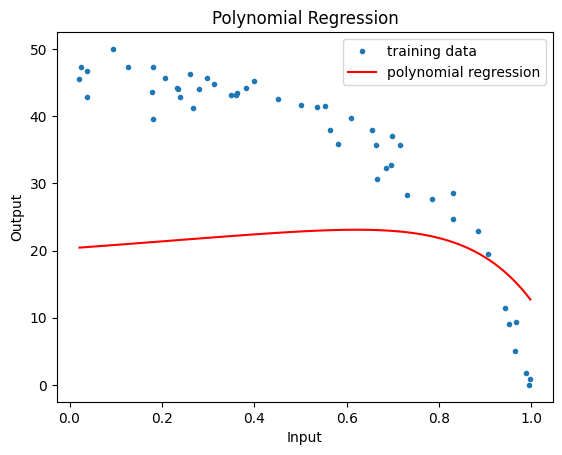

Polynomial regression with grade 10
Regularization parameters: 1.0 1.0
Polynomial regression found in: 252 iterations
Found values for coefficients:  [ 1.64583199e+01  4.49315401e+00  1.28899012e+00  3.03027309e-03
 -6.24970689e-01 -9.70464192e-01 -1.17450083e+00 -1.29973226e+00
 -1.37778091e+00 -1.42616688e+00 -1.45527483e+00]


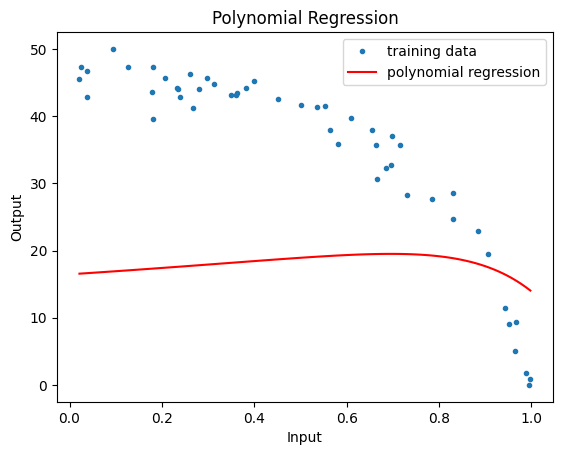

Polynomial regression with grade 13
Regularization parameters: 0.0 0.0
Polynomial regression found in: 6624 iterations
Found values for coefficients:  [ 46.34957995  -9.76105374  18.82291871 -21.72498314 -36.0637004
 -16.12930265   8.06176912  20.81841498  20.70278145  11.97354817
  -0.09538261 -10.95782389 -17.22672091 -16.61781043]


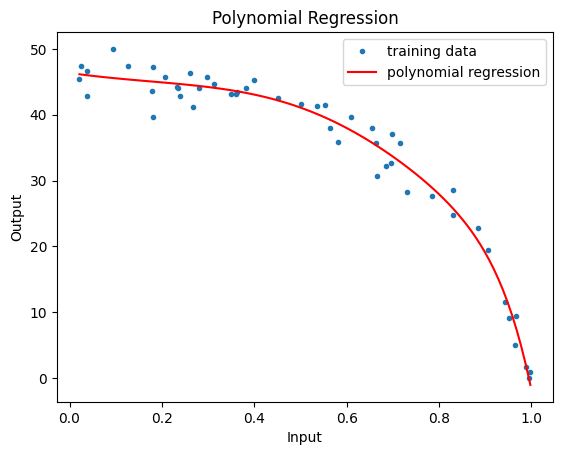

Polynomial regression with grade 13
Regularization parameters: 0.0 0.33
Polynomial regression found in: 147 iterations
Found values for coefficients:  [26.79425127  5.70700836  0.65774244 -1.13599539 -1.90123109 -2.25510908
 -2.42205374 -2.4929879  -2.51354495 -2.50571237 -2.48141576 -2.44750931
 -2.40810074 -2.36572072]


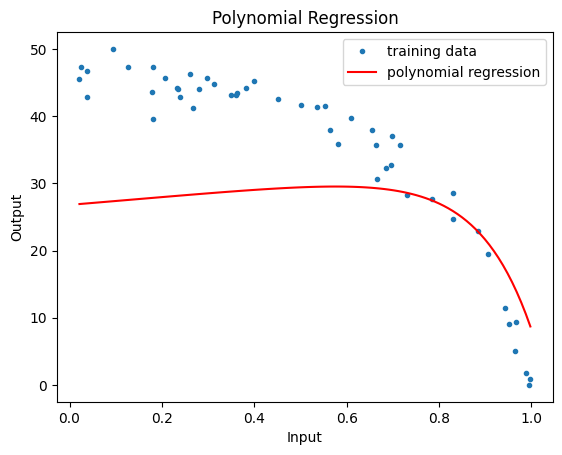

Polynomial regression with grade 13
Regularization parameters: 0.0 0.66
Polynomial regression found in: 162 iterations
Found values for coefficients:  [20.36424977  5.26116314  1.37583608 -0.11229006 -0.80616142 -1.16531608
 -1.36502657 -1.476966   -1.53833819 -1.56895012 -1.5802113  -1.579061
 -1.56986986 -1.55545856]


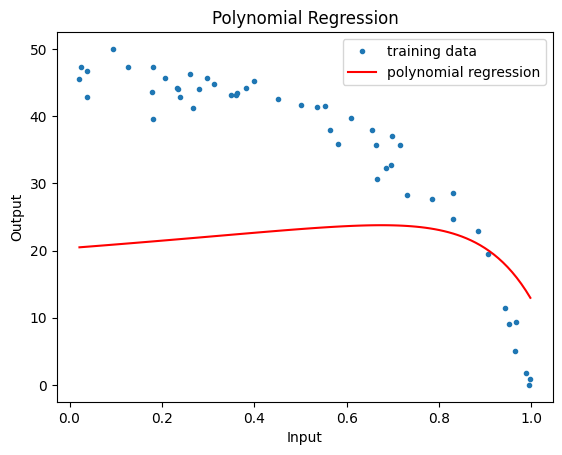

Polynomial regression with grade 13
Regularization parameters: 0.0 1.0
Polynomial regression found in: 171 iterations
Found values for coefficients:  [16.53572159  4.69755081  1.55669475  0.30920418 -0.29060781 -0.61568612
 -0.80420593 -0.9173     -0.98547522 -1.02568151 -1.04790284 -1.0582863
 -1.06075016 -1.05786009]


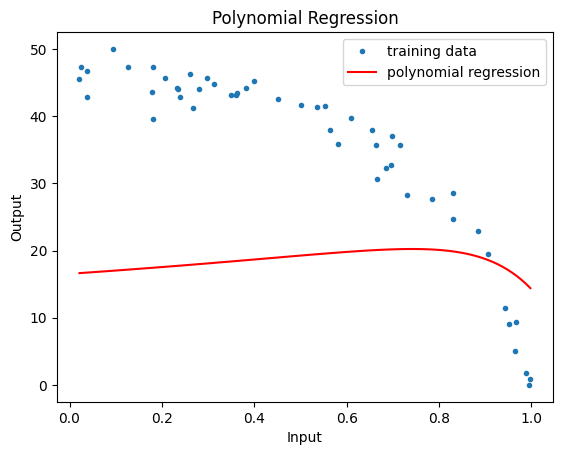

Polynomial regression with grade 13
Regularization parameters: 0.33 0.0
Polynomial regression found in: 10001 iterations
Found values for coefficients:  [ 46.70864763 -16.23720908  37.44149787 -17.45002246 -56.68332694
 -40.28771753  -2.74233082  28.57993854  43.9058891   42.68802333
  27.63344453   2.01636966 -31.30710418 -70.15735811]


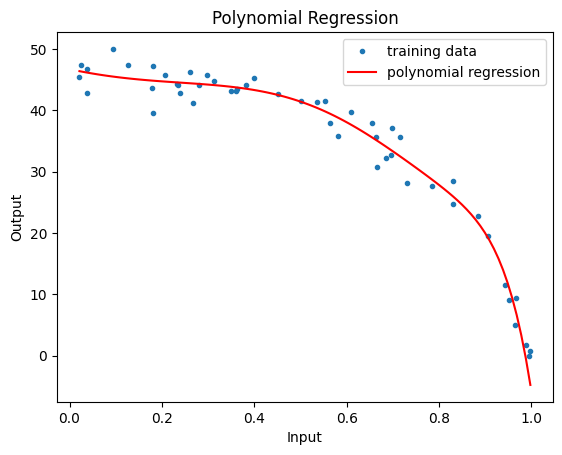

Polynomial regression with grade 13
Regularization parameters: 0.33 0.33
Polynomial regression found in: 242 iterations
Found values for coefficients:  [26.8108516   5.72516945  0.64153654 -1.17766904 -1.95798776 -2.32862193
 -2.51175929 -2.59933651 -2.6344978  -2.6395222  -2.62674903 -2.60336589
 -2.57371051 -2.54046701]


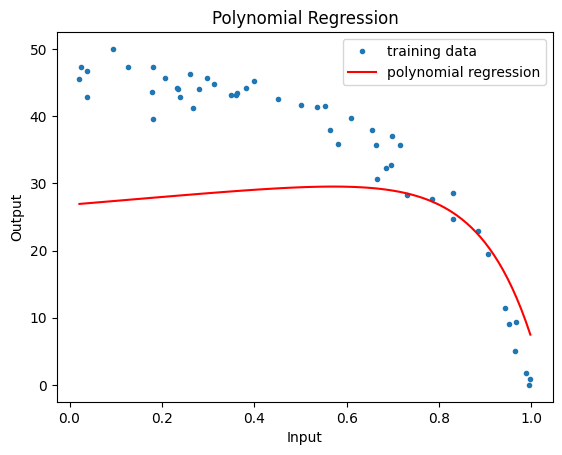

Polynomial regression with grade 13
Regularization parameters: 0.33 0.66
Polynomial regression found in: 317 iterations
Found values for coefficients:  [20.36635587  5.24358907  1.34165804 -0.16326051 -0.86698609 -1.23638321
 -1.44318733 -1.56189699 -1.62925442 -1.66518659 -1.68125802 -1.68451002
 -1.67938127 -1.66874359]


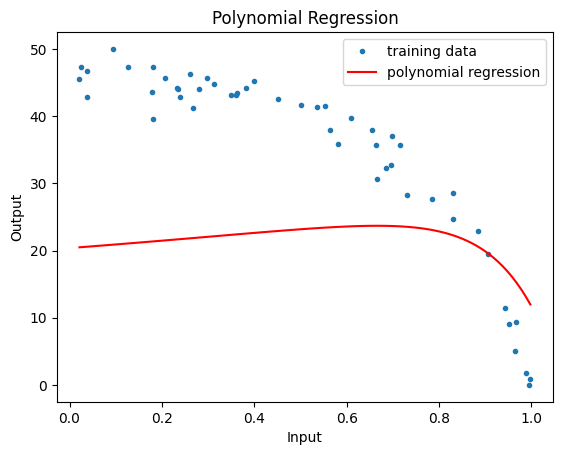

Polynomial regression with grade 13
Regularization parameters: 0.33 1.0
Polynomial regression found in: 281 iterations
Found values for coefficients:  [16.53003657  4.67021835  1.51696629  0.26171921 -0.34579748 -0.67683158
 -0.87026234 -0.98748188 -1.05933366 -1.10283808 -1.12803014 -1.14111025
 -1.1460427  -1.14542893]


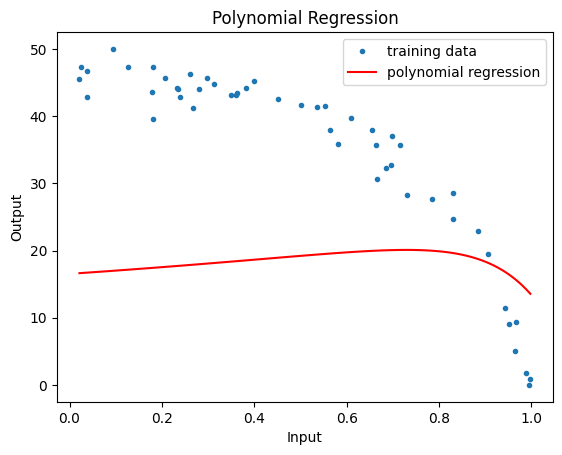

Polynomial regression with grade 13
Regularization parameters: 0.66 0.0
Polynomial regression found in: 10001 iterations
Found values for coefficients:  [  46.9627081   -20.64260239   48.38146775   -8.62334312  -69.51072359
  -63.26542777  -19.06738771   29.02102696   62.84390032   74.55600067
   61.24269524   22.19070017  -42.33759083 -131.63798952]


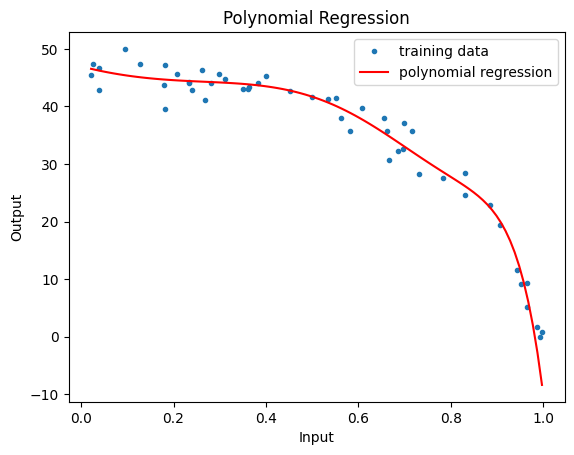

Polynomial regression with grade 13
Regularization parameters: 0.66 0.33
Polynomial regression found in: 280 iterations
Found values for coefficients:  [26.8303852   5.73235008  0.62506644 -1.21673121 -2.01722317 -2.40572419
 -2.6048024  -2.70671724 -2.75487806 -2.77177795 -2.7699277  -2.75664906
 -2.7363867  -2.71191155]


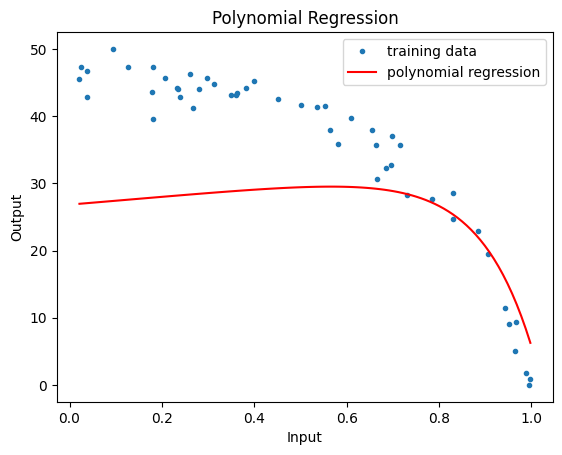

Polynomial regression with grade 13
Regularization parameters: 0.66 0.66
Polynomial regression found in: 287 iterations
Found values for coefficients:  [20.37072027  5.22463885  1.30534202 -0.21308388 -0.92774673 -1.30629225
 -1.52092745 -1.64647349 -1.71988981 -1.76125954 -1.78226159 -1.7900228
 -1.78904714 -1.78225723]


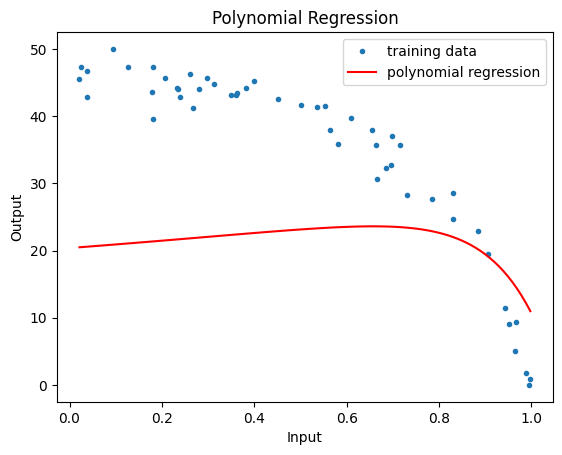

Polynomial regression with grade 13
Regularization parameters: 0.66 1.0
Polynomial regression found in: 297 iterations
Found values for coefficients:  [16.52377512  4.64350027  1.47767401  0.2133581  -0.40122278 -0.73800485
 -0.93627136 -1.05765298 -1.13315346 -1.17990409 -1.20801931 -1.22375778
 -1.23112745 -1.23276322]


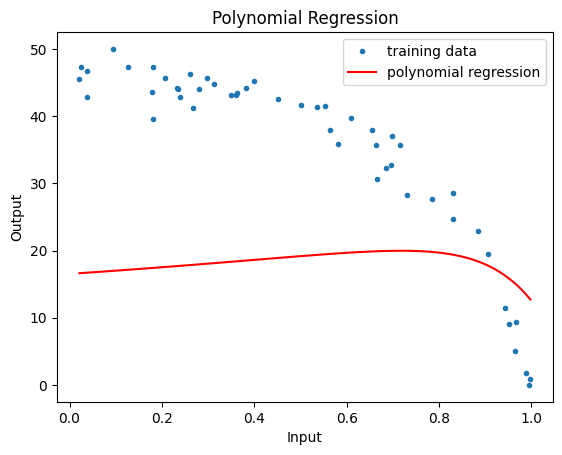

Polynomial regression with grade 13
Regularization parameters: 1.0 0.0
Polynomial regression found in: 10001 iterations
Found values for coefficients:  [  47.21989091  -25.20148407   59.73746962    0.36749898  -82.86529151
  -86.88670533  -35.71797072   29.61340652   82.37475995  107.27771528
   95.67747944   42.79296486  -53.75306521 -194.70672499]


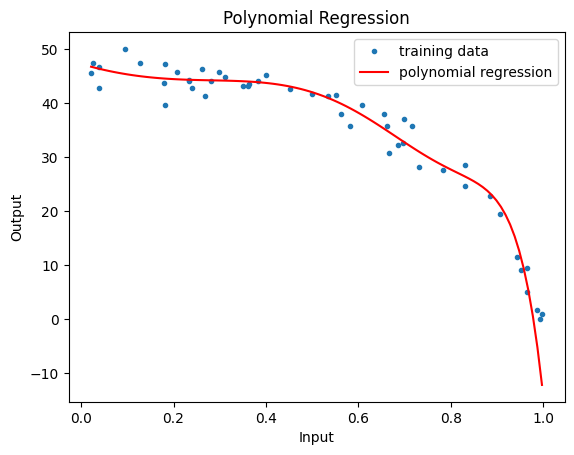

Polynomial regression with grade 13
Regularization parameters: 1.0 0.33
Polynomial regression found in: 316 iterations
Found values for coefficients:  [26.85056953  5.73972585  0.60803722 -1.25701141 -2.07826203 -2.48517371
 -2.70066714 -2.8173478  -2.87889917 -2.9080341  -2.91743726 -2.9145684
 -2.9039828  -2.88854121]


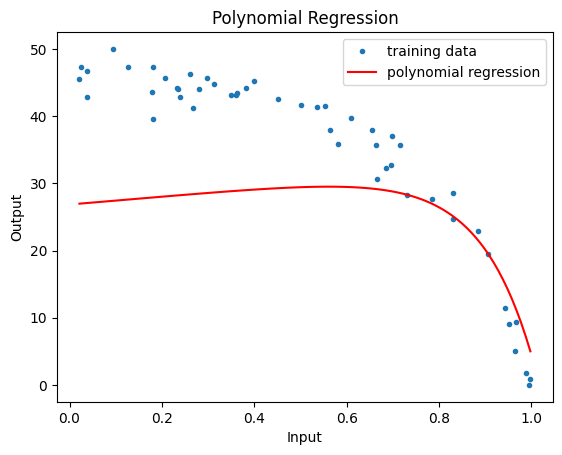

Polynomial regression with grade 13
Regularization parameters: 1.0 0.66
Polynomial regression found in: 328 iterations
Found values for coefficients:  [20.37522218  5.20511203  1.2679177  -0.2644143  -0.99035372 -1.37832107
 -1.60102589 -1.73361363 -1.81327144 -1.86024331 -1.88632553 -1.8987328
 -1.90203624 -1.89921079]


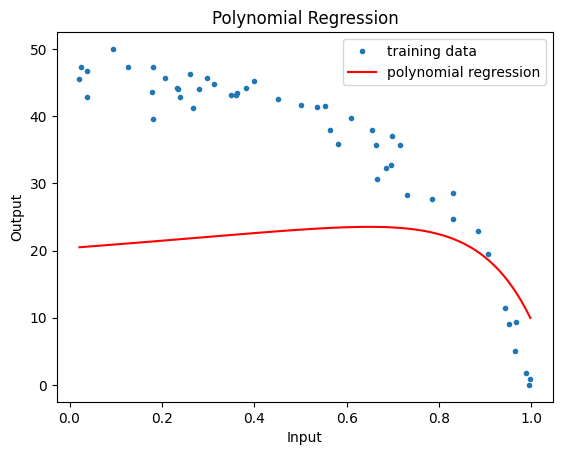

Polynomial regression with grade 13
Regularization parameters: 1.0 1.0
Polynomial regression found in: 321 iterations
Found values for coefficients:  [16.51732531  4.61597017  1.43719042  0.16352958 -0.45832569 -0.80103362
 -1.0042814  -1.12995016 -1.20920945 -1.25930471 -1.29043189 -1.30890948
 -1.31879037 -1.32274396]


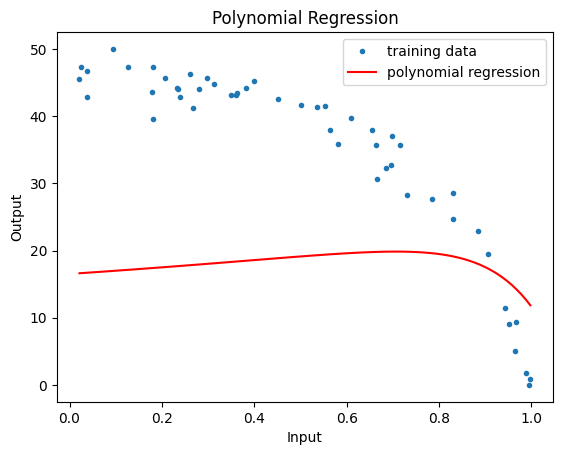

In [15]:
mySGD.test_poly(poly_graph_x, poly_data_x, poly_data_y, True)

# Second Task

## Gradient Descent with different Batch sizes

In [38]:
mySGD.test_GD()

In [39]:
mySGD.show_results()

╒══════════════╤═══════════════════════════╤════════════════════╤═════════════╤══════════════╕
│   Batch Size │ found point               │   Iterations taken │ Converged   │ Time taken   │
╞══════════════╪═══════════════════════════╪════════════════════╪═════════════╪══════════════╡
│            1 │ [2.4620123  0.10649351]   │              10001 │ False       │ 31.2202s     │
├──────────────┼───────────────────────────┼────────────────────┼─────────────┼──────────────┤
│           10 │ [2.44592705 1.03741947]   │              10001 │ False       │ 46.2627s     │
├──────────────┼───────────────────────────┼────────────────────┼─────────────┼──────────────┤
│           30 │ [2.40821791 2.5930403 ]   │              10001 │ False       │ 71.8382s     │
├──────────────┼───────────────────────────┼────────────────────┼─────────────┼──────────────┤
│           50 │ [2.46625269 1.23469975]   │              10001 │ False       │ 124.2223s    │
├──────────────┼───────────────────────────┼──────

## Testing Gradient descent with Exponential scheduler

In [40]:
# Exponential scheduler
print("\n===============Exponential Scheduler======================\n")
mySGD.test_GD('exponential', True)
mySGD.show_results()


===============Exponential Scheduler======================

╒══════════════╤═════════════════════════╤════════════════════╤═════════════╤══════════════╕
│   Batch Size │ found point             │   Iterations taken │ Converged   │ Time taken   │
╞══════════════╪═════════════════════════╪════════════════════╪═════════════╪══════════════╡
│            1 │ [2.44943712 0.21530955] │                121 │ True        │ 0.0406s      │
├──────────────┼─────────────────────────┼────────────────────┼─────────────┼──────────────┤
│            2 │ [2.44096773 0.21050012] │                115 │ True        │ 0.0203s      │
├──────────────┼─────────────────────────┼────────────────────┼─────────────┼──────────────┤
│            3 │ [2.4250087  0.20530479] │                 99 │ True        │ 0.0183s      │
├──────────────┼─────────────────────────┼────────────────────┼─────────────┼──────────────┤
│            4 │ [2.4184379  0.20394694] │                 87 │ True        │ 0.0191s      │
├────────

# Third task

## Gradient Descent 2.0

In [41]:
table = np.array(['Function', 'Method', 'found point', 'Converged', 'Iterations taken', 'Time taken', 'Used Memory'])

In [42]:
class GD:  
  #static members
  MAX_ITERATIONS = 10000

  normal_names = ['x^2 + 2xy + 3y^2',
         '4(x - 1)^2 + 3(y - 3)^2 + 4xy - 3',
         '35x^2 + 71xy + 45y^2 - 8x + 62y + 11',
         '15x^2 + 3y^2 - 7x + 11y - 8']

  normal_functions = [lambda pars : pars[0]**2 + 2*pars[0]*pars[1] + 3*pars[1]**2,
              lambda pars : 4 * (pars[0] - 1)**2 + 3 * (pars[1] - 3)**2 + 4 * pars[0] * pars[1] - 3,
              lambda pars : 35 * pars[0] ** 2 + 71 * pars[0] * pars[1] + 45 * pars[1]**2 - 8 * pars[0] + 62 * pars[1] + 11,
              lambda pars : 15 * pars[0] ** 2 + 3 * pars[1] ** 2 - 7 * pars[0] + 11 * pars[1] - 8]

  normal_derivates = [lambda pars : np.array([2*pars[0] + 2*pars[1], 2*pars[0] + 6*pars[1]]),
              lambda pars : np.array([8*(pars[0] - 1) + 4*pars[1], 6*(pars[1] - 3) + 4 * pars[0]]),
              lambda pars : np.array([70 * pars[0] + 71 * pars[1] - 8, 90 * pars[1] + 71 * pars[0] + 62]),
              lambda pars : np.array([30 * pars[0] - 7, 6 * pars[1] + 11])]

  names_with_scaling = ['1000000x^2 + 2xy + 3y^2',
         '1000000(x - 1)^2 + 3(y - 3)^2 + 4xy - 3',
         '35x^2 + 71xy + 1000000y^2 - 8x + 62y + 11',
         '15x^2 + 1000000y^2 - 7x + y - 8']

  functions_with_scaling = [lambda pars : 1000000*pars[0]**2 + 2*pars[0]*pars[1] + 3*pars[1]**2,
              lambda pars : 1000000 * (pars[0] - 1)**2 + 3 * (pars[1] - 3)**2 + 4 * pars[0] * pars[1] - 3,
              lambda pars : 35 * pars[0] ** 2 + 71 * pars[0] * pars[1] + 1000000 * pars[1]**2 - 8 * pars[0] + 62 * pars[1] + 11,
              lambda pars : 15 * pars[0] ** 2 + 1000000 * pars[1] ** 2 - 7 * pars[0] + pars[1] - 8]

  derivates_with_scaling = [lambda pars : np.array([2000000*pars[0] + 2*pars[1], 2*pars[0] + 6*pars[1]]),
              lambda pars : np.array([2000000*(pars[0] - 1) + 4*pars[1], 6*(pars[1] - 3) + 4 * pars[0]]),
              lambda pars : np.array([70 * pars[0] + 71 * pars[1] - 8, 2000000 * pars[1] + 71 * pars[0] + 62]),
              lambda pars : np.array([30 * pars[0] - 7, 2000000 * pars[1] + 1])]

  default_points = [np.array([-10,10]),np.array([-10,10]),np.array([-10,10]),np.array([-10,10])]

  #setters
  def set_initial_points(self, points):
    if (points is None):
      return
    if (points.size != self.n):
      return
    self.initial_points = points[:]

  def set_epsilon(self, epsilon):
    self.epsilon = epsilon

  def set_step(self, step):
    self.step = step

  def set_points(self, points):
    self.points = points

  def set_derivate(self, derivate):
    self.derivate = derivate

  def set_computer(self, name):
    self.gradient_computer = name
    if (name in self.gradient_computers.keys()):
      self.epsilon = 0.0000001
      self.step = 0.001
    if (name == 'nesterov'):
      #Recommended values for Nesterov Momentum
      self.momentum = 0.9
      self.step = 0.001
      self.vLast = 0
      self.vLast = 0
    if (name == 'adagrad' or name == 'rmsprop' or name == 'adam'):
      self.step = 1
      self.gradient_sum = 0
    if (name == 'rmsprop'):
      self.rho = 0.9
    if (name == 'adam'):
      self.beta1 = 0.9
      self.beta2 = 0.999
      self.grad_sum = 0
      self.sq_grad_sum = 0

  #Constructor
  def __init__(self, n = 2, initial_points=None, epsilon=0.0000001, step = 0.01):
    table = np.array([])
    self.n = n
    if (initial_points is None):
      self.initial_points = np.zeros(n)
    else:
      self.initial_points = initial_points
    self.epsilon = epsilon
    self.step = step
    self.gradient_computer = None
    #Gradient computers
    self.gradient_computers = {'nesterov' : self.nesterov,
                               'adagrad' : self.adagrad,
                               'rmsprop' : self.rmsprop,
                               'adam' : self.adam}

  # =================Task3================== #
  # Gradient Computers
  def nesterov(self, difArray):
    v = self.momentum * self.vLast - self.step * self.derivate(self.points + self.momentum * self.vLast)
    self.vLast = v
    return v

  def adagrad(self, grad):
    self.gradient_sum += (grad ** 2.0);
    vector_sqrt = np.vectorize(sqrt)
    return -1 * (self.step * grad) / (vector_sqrt(self.gradient_sum + self.epsilon))

  def rmsprop(self, grad):
    self.gradient_sum = self.gradient_sum * self.rho + ((grad ** 2.0) * (1 - self.rho));
    vector_sqrt = np.vectorize(sqrt)
    return -1 * (self.step * grad) / (vector_sqrt(self.gradient_sum + self.epsilon))

  def adam(self, grad):
    self.grad_sum = self.grad_sum * self.beta1 + grad * (1 - self.beta1)
    self.sq_grad_sum = self.sq_grad_sum * self.beta2 + ((grad ** 2.0) * (1 - self.beta2))
    vector_sqrt = np.vectorize(sqrt)
    return -1 * (self.step * self.grad_sum) / (vector_sqrt(self.sq_grad_sum + self.epsilon))

  # =================Task3================== #



  def gradient_descent(self, function, derivate, n = 2, initial_points=None):
    iteration = 0
    self.set_initial_points(initial_points)
    self.set_derivate(derivate)
    last_points = ini_points = self.initial_points[:]
    points = last_points[:]
    ans = np.array(points[:])
    dif = np.zeros(points.size);
    while iteration <= self.MAX_ITERATIONS:
      self.set_points(points)
      difArray = derivate(points)
      if (self.gradient_computer is None):
        dif = -1 * self.step * difArray
      else:
        dif = self.gradient_computers[self.gradient_computer](difArray)
      
      points = last_points[:] + dif
      ans = np.append(ans, points[:])

      result1 = function(last_points)
      result2 = function(points)
      if (lin.norm(difArray) < self.epsilon) or (lin.norm(points - last_points) < self.epsilon) or (abs(result2 - result1) < self.epsilon):
        break
      iteration += 1
      last_points = points[::]
    return ans, iteration, last_points
  #gradient_descent(functions[0], derivates[0], 2, False, np.array([5.0, 5.0])) 





  # ======================Testing and Drawing======================= #

  def plot_graph(self, function,derivate, initial_points=default_points, sizex=10, sizey=10):
    x = np.linspace(-sizex, sizex, 100)
    y = np.linspace(-sizey, sizey, 100)
    X, Y = np.meshgrid(x, y)
    F = function(np.array([X, Y]))

    # ===============Changed================= #

    start_time = time.time()
    process = psutil.Process(os.getpid())
    tracemalloc.start()
    points, iter, last_points = self.gradient_descent(function, derivate, 2, initial_points)
    total_mem = tracemalloc.get_traced_memory()[1]
    tracemalloc.stop()
    total_time = round(time.time() - start_time, 4)

    # ===============Changed================= #

    print("Found point: ", last_points)
    if (iter > 10000):
      print("did not converge")
    else:
      print("in", iter, "iterations")
    fig, ax = plt.subplots(figsize=(8, 6))
    contour = ax.contour(X, Y, F, levels=20, cmap='coolwarm')
    x_0 = np.array(points[0:len(points):2])
    y_0 = np.array(points[1:len(points):2])
    ax.plot(x_0, y_0, linestyle = '--', color='green')
    ax.set_xlabel('x')
    ax.set_ylabel('y')
    ax.clabel(contour, inline=True, fontsize=8)
    plt.show()
    return last_points, iter, total_time, total_mem

  def drawing_module(self, names, functions, derivates, points):
    global table
    for name, function, derivate, point  in zip(names, functions, derivates, points):
      print(f"Computing for {name}:")
      result = self.plot_graph(function,derivate, point, 15, 15)
      table = np.append(table, np.array([name, 
                                         self.gradient_computer,
                                         result[0], result[1] <= GD.MAX_ITERATIONS,
                                         result[1], str(result[2]) + ' s', str(result[3]) + ' bytes']))

  def test_normal(self, gradient_computer):
    self.set_computer(gradient_computer)
    self.drawing_module(GD.normal_names, GD.normal_functions, GD.normal_derivates, points=GD.default_points)


  def test_scaling(self, gradient_computer):
    self.set_computer(gradient_computer)
    self.drawing_module(GD.names_with_scaling, GD.functions_with_scaling, GD.derivates_with_scaling, points=GD.default_points)

  # ======================Testing and Drawing======================= #

#Create instance
myGD = GD()

In [43]:
def show_results():
  global table
  table = np.reshape(table, ((int)(table.size / 7), 7))
  print(tabulate(table, headers='firstrow', tablefmt='fancy_grid'))

## Normal testing

In [44]:
table = np.array(['Function', 'Method', 'found point', 'Converged', 'Iterations taken', 'Time taken', 'Used Memory'])

### Testing Nesterov Momentum

Computing for x^2 + 2xy + 3y^2:
Found point:  [-0.00233097  0.00096552]
in 657 iterations


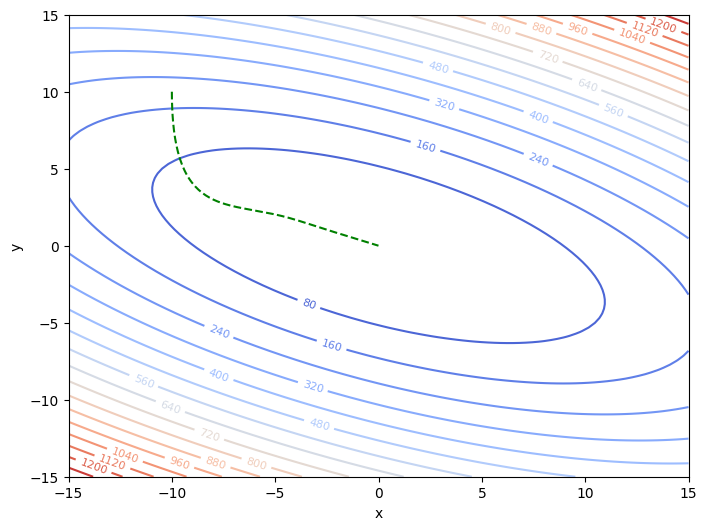

<ipython-input-42-680eb2dfd174>:196: VisibleDeprecationWarning: Creating an ndarray from ragged nested sequences (which is a list-or-tuple of lists-or-tuples-or ndarrays with different lengths or shapes) is deprecated. If you meant to do this, you must specify 'dtype=object' when creating the ndarray.
  table = np.append(table, np.array([name,


Computing for 4(x - 1)^2 + 3(y - 3)^2 + 4xy - 3:
Found point:  [-0.750481    3.50058487]
in 202 iterations


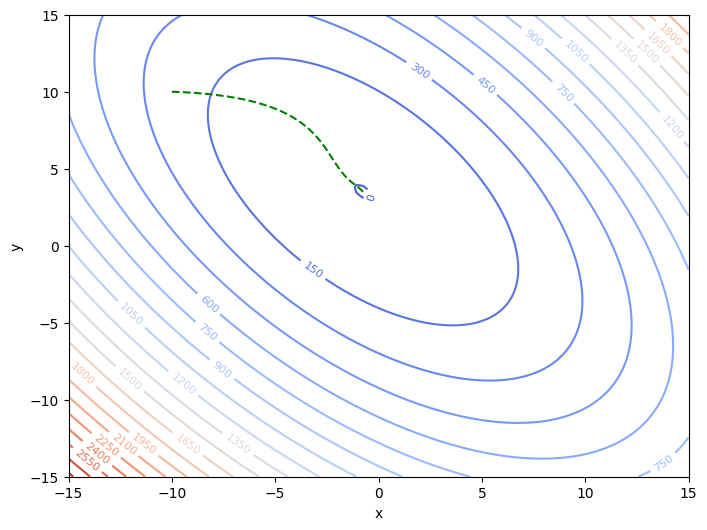

Computing for 35x^2 + 71xy + 45y^2 - 8x + 62y + 11:
Found point:  [ 4.06728844 -3.89744583]
in 167 iterations


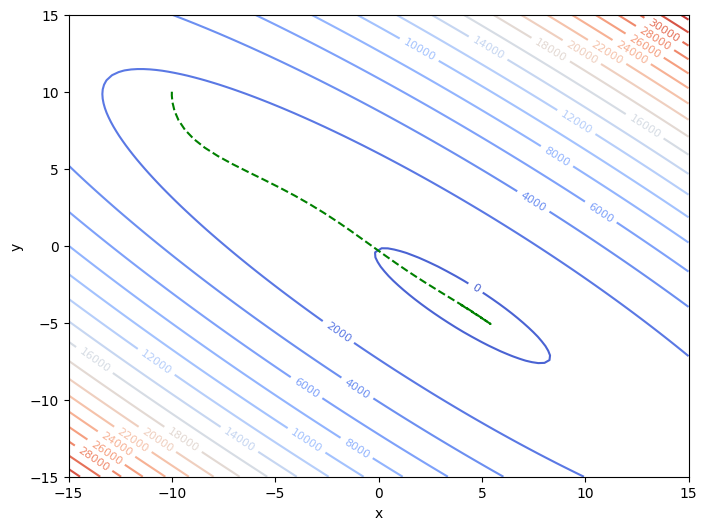

Computing for 15x^2 + 3y^2 - 7x + 11y - 8:
Found point:  [ 0.23298594 -1.83311252]
in 150 iterations


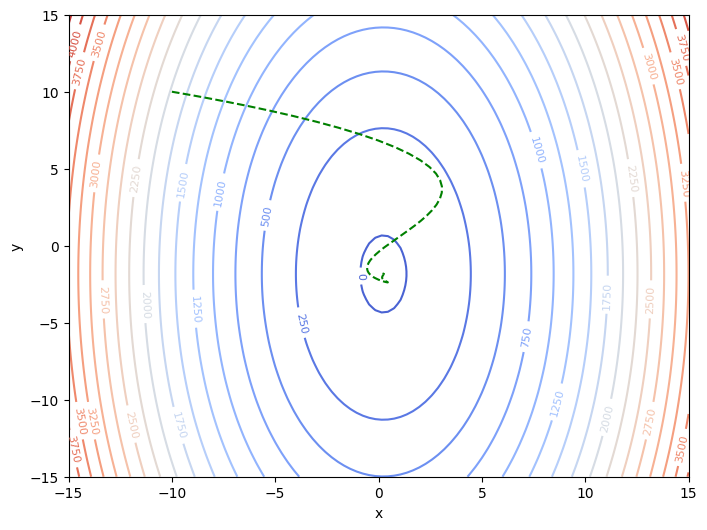

In [45]:
myGD.test_normal('nesterov')

### Testing AdaGrad

Computing for x^2 + 2xy + 3y^2:
Found point:  [-0.0009542   0.00087548]
in 283 iterations


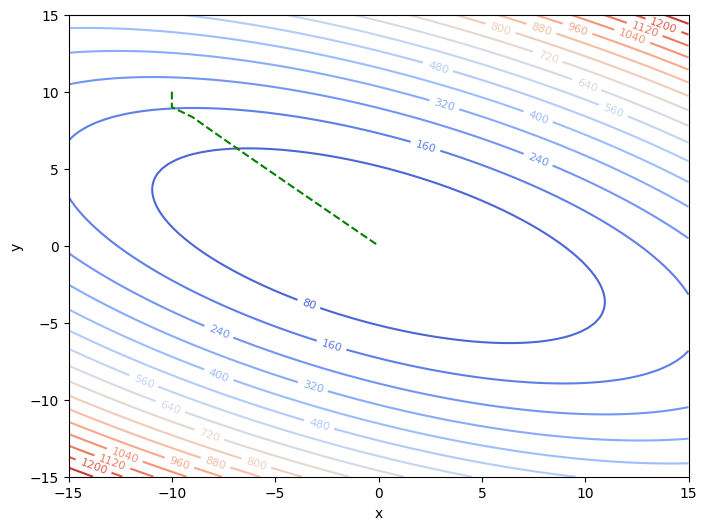

<ipython-input-42-680eb2dfd174>:196: VisibleDeprecationWarning: Creating an ndarray from ragged nested sequences (which is a list-or-tuple of lists-or-tuples-or ndarrays with different lengths or shapes) is deprecated. If you meant to do this, you must specify 'dtype=object' when creating the ndarray.
  table = np.append(table, np.array([name,


Computing for 4(x - 1)^2 + 3(y - 3)^2 + 4xy - 3:
Found point:  [-0.75075335  3.50104522]
in 421 iterations


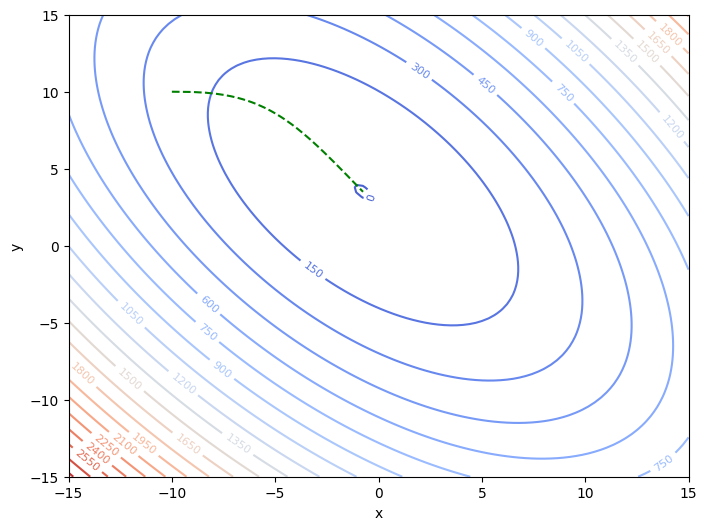

Computing for 35x^2 + 71xy + 45y^2 - 8x + 62y + 11:
Found point:  [ 4.06763875 -3.89772291]
in 670 iterations


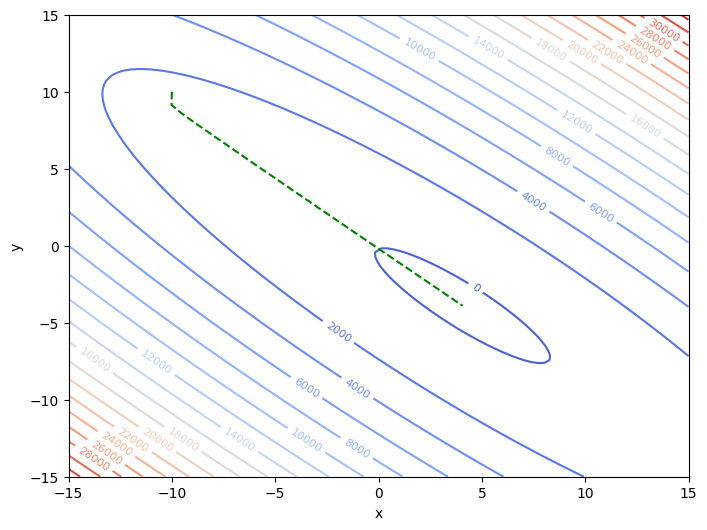

Computing for 15x^2 + 3y^2 - 7x + 11y - 8:
Found point:  [ 0.23333333 -1.8316329 ]
in 1522 iterations


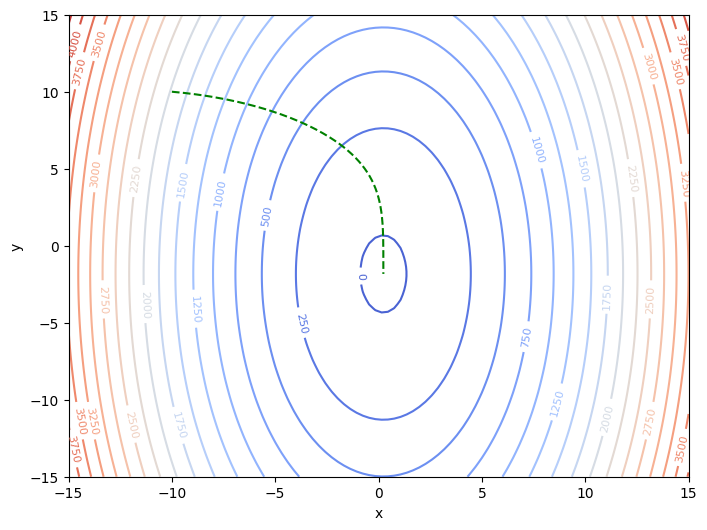

In [46]:
myGD.test_normal('adagrad')

### Testing RMSprop

Computing for x^2 + 2xy + 3y^2:
Found point:  [-1.28443414e-04  9.39503457e-05]
in 24 iterations


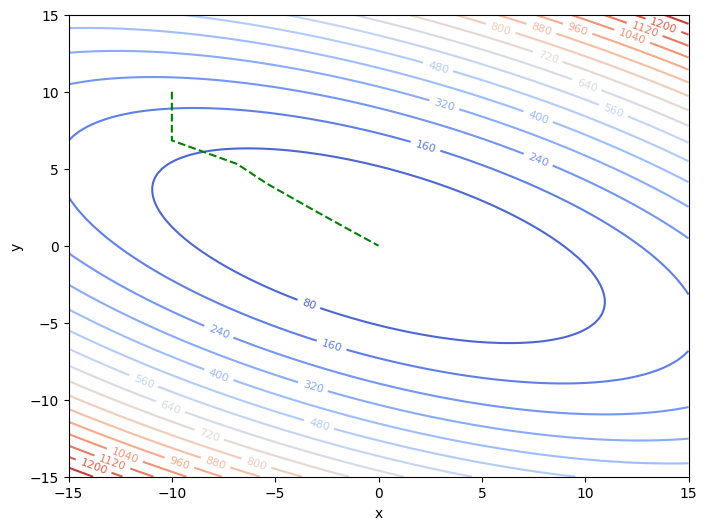

<ipython-input-42-680eb2dfd174>:196: VisibleDeprecationWarning: Creating an ndarray from ragged nested sequences (which is a list-or-tuple of lists-or-tuples-or ndarrays with different lengths or shapes) is deprecated. If you meant to do this, you must specify 'dtype=object' when creating the ndarray.
  table = np.append(table, np.array([name,


Computing for 4(x - 1)^2 + 3(y - 3)^2 + 4xy - 3:
Found point:  [-1.25000036  2.99999964]
in 306 iterations


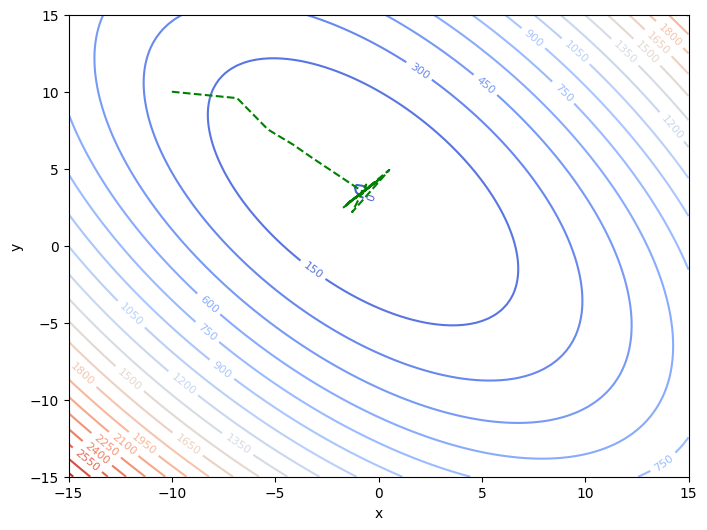

Computing for 35x^2 + 71xy + 45y^2 - 8x + 62y + 11:
Found point:  [ 3.56830815 -4.39833204]
in 337 iterations


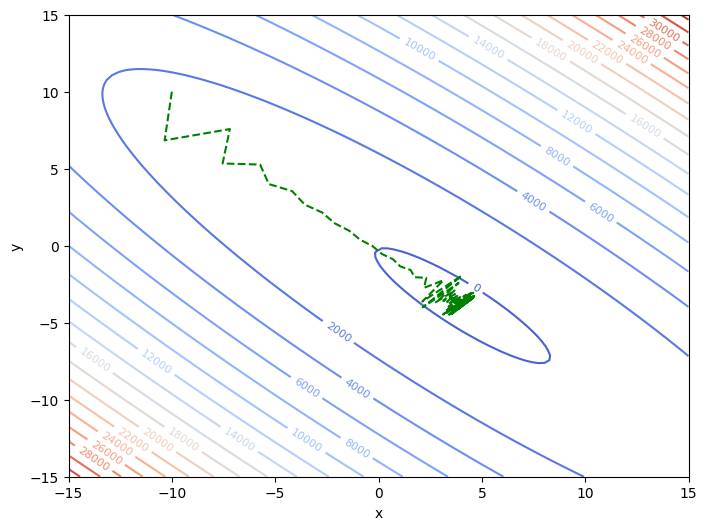

Computing for 15x^2 + 3y^2 - 7x + 11y - 8:
Found point:  [ 0.23333333 -1.83323658]
in 44 iterations


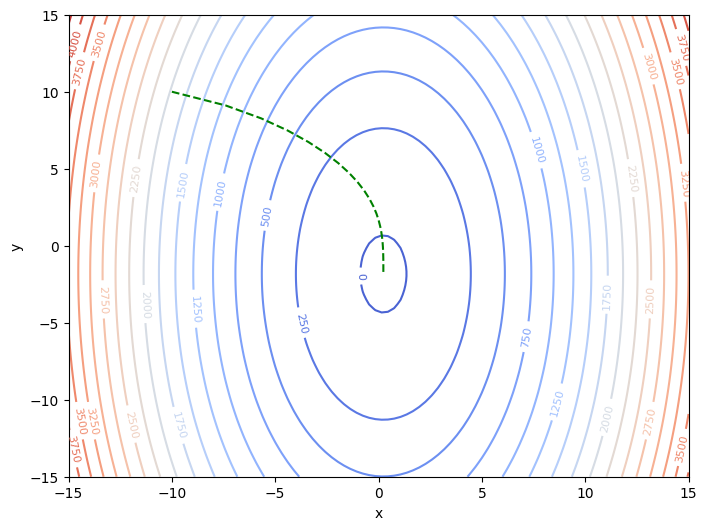

In [47]:
myGD.test_normal('rmsprop')

### Testing Adam

Computing for x^2 + 2xy + 3y^2:
Found point:  [ 0.00043174 -0.00011258]
in 174 iterations


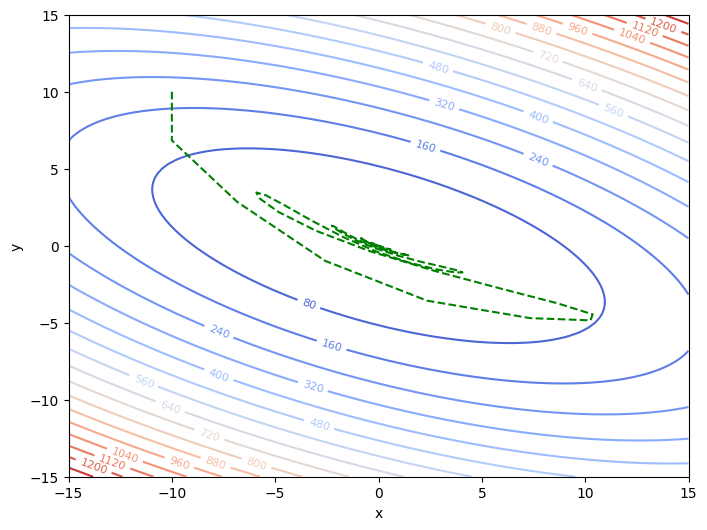

<ipython-input-42-680eb2dfd174>:196: VisibleDeprecationWarning: Creating an ndarray from ragged nested sequences (which is a list-or-tuple of lists-or-tuples-or ndarrays with different lengths or shapes) is deprecated. If you meant to do this, you must specify 'dtype=object' when creating the ndarray.
  table = np.append(table, np.array([name,


Computing for 4(x - 1)^2 + 3(y - 3)^2 + 4xy - 3:
Found point:  [-0.75105625  3.50151914]
in 164 iterations


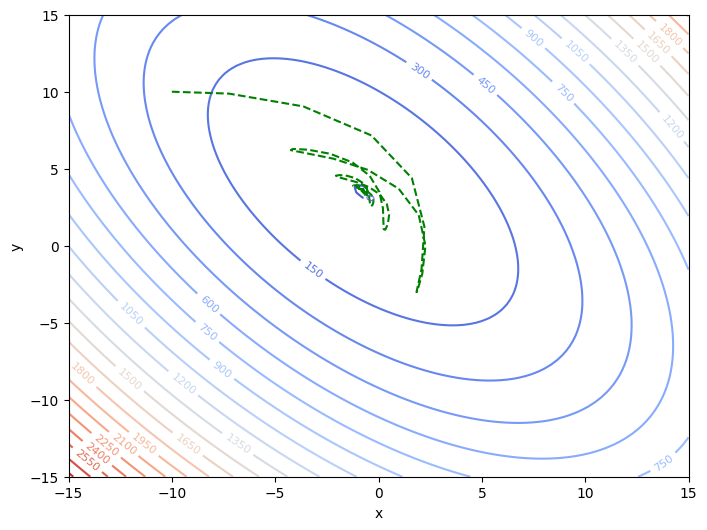

Computing for 35x^2 + 71xy + 45y^2 - 8x + 62y + 11:
Found point:  [ 4.06868329 -3.89862319]
in 199 iterations


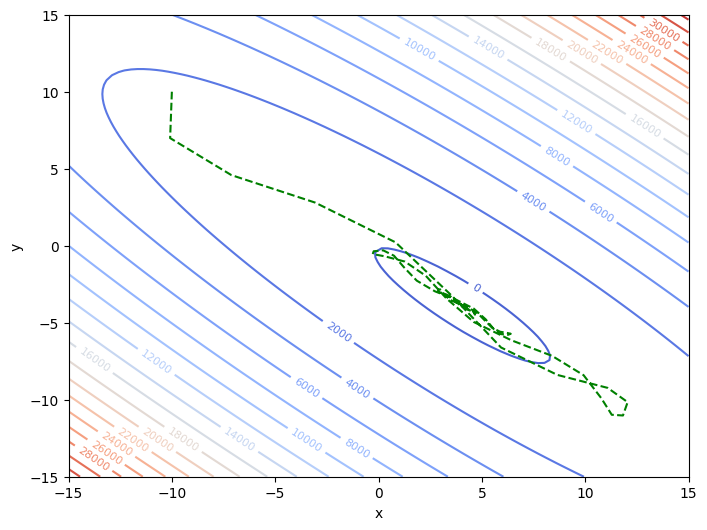

Computing for 15x^2 + 3y^2 - 7x + 11y - 8:
Found point:  [ 0.23368433 -1.83337255]
in 193 iterations


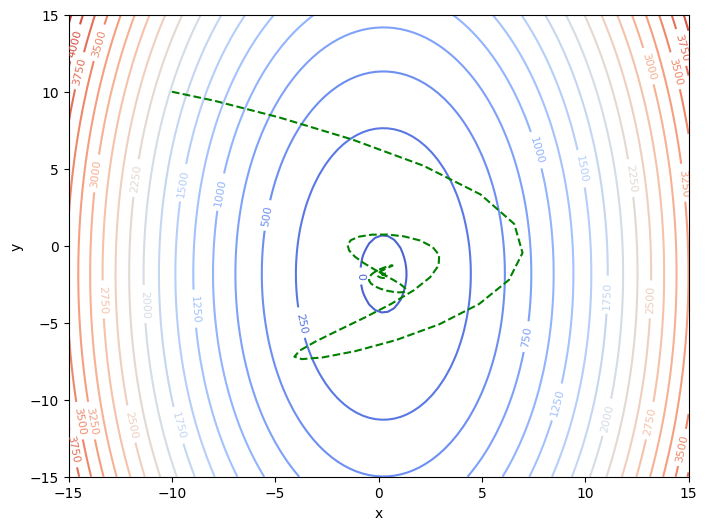

In [48]:
myGD.test_normal('adam')

### Testing results

In [53]:
show_results()

╒═══════════════════════════════════════════╤══════════╤═══════════════════════════════════╤═════════════╤════════════════════╤══════════════╤═══════════════╕
│ Function                                  │ Method   │ found point                       │ Converged   │   Iterations taken │ Time taken   │ Used Memory   │
╞═══════════════════════════════════════════╪══════════╪═══════════════════════════════════╪═════════════╪════════════════════╪══════════════╪═══════════════╡
│ x^2 + 2xy + 3y^2                          │ nesterov │ [-0.00233097  0.00096552]         │ True        │                657 │ 0.0823 s     │ 26931 bytes   │
├───────────────────────────────────────────┼──────────┼───────────────────────────────────┼─────────────┼────────────────────┼──────────────┼───────────────┤
│ 4(x - 1)^2 + 3(y - 3)^2 + 4xy - 3         │ nesterov │ [-0.750481    3.50058487]         │ True        │                202 │ 0.0445 s     │ 13064 bytes   │
├───────────────────────────────────────────┼─

## Scaled testing

### Testing Nesterov Momentum

Computing for 1000000x^2 + 2xy + 3y^2:


<ipython-input-42-680eb2dfd174>:25: RuntimeWarning: overflow encountered in double_scalars
  functions_with_scaling = [lambda pars : 1000000*pars[0]**2 + 2*pars[0]*pars[1] + 3*pars[1]**2,
<ipython-input-42-680eb2dfd174>:144: RuntimeWarning: invalid value encountered in double_scalars
  if (lin.norm(difArray) < self.epsilon) or (lin.norm(points - last_points) < self.epsilon) or (abs(result2 - result1) < self.epsilon):
<ipython-input-42-680eb2dfd174>:30: RuntimeWarning: overflow encountered in double_scalars
  derivates_with_scaling = [lambda pars : np.array([2000000*pars[0] + 2*pars[1], 2*pars[0] + 6*pars[1]]),
<ipython-input-42-680eb2dfd174>:99: RuntimeWarning: invalid value encountered in subtract
  v = self.momentum * self.vLast - self.step * self.derivate(self.points + self.momentum * self.vLast)


Found point:  [nan nan]
did not converge


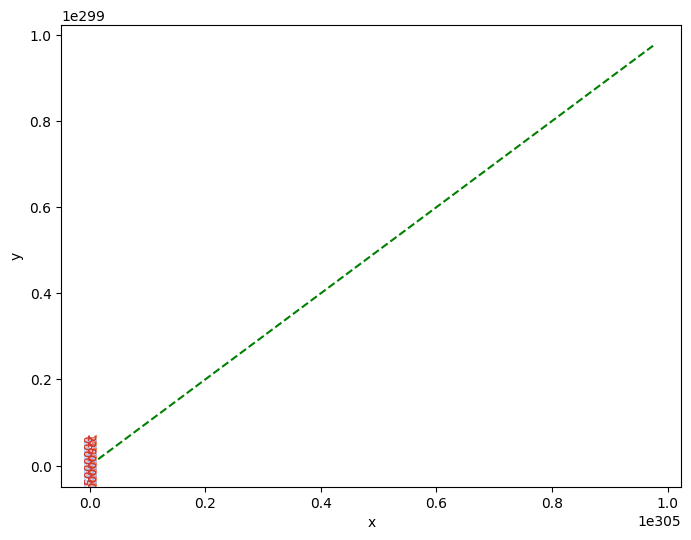

<ipython-input-42-680eb2dfd174>:196: VisibleDeprecationWarning: Creating an ndarray from ragged nested sequences (which is a list-or-tuple of lists-or-tuples-or ndarrays with different lengths or shapes) is deprecated. If you meant to do this, you must specify 'dtype=object' when creating the ndarray.
  table = np.append(table, np.array([name,


Computing for 1000000(x - 1)^2 + 3(y - 3)^2 + 4xy - 3:
Found point:  [nan nan]
did not converge


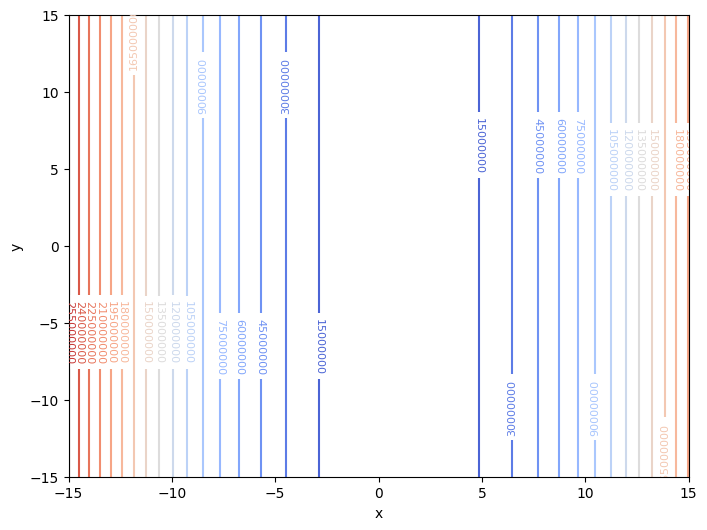

Computing for 35x^2 + 71xy + 1000000y^2 - 8x + 62y + 11:
Found point:  [nan nan]
did not converge


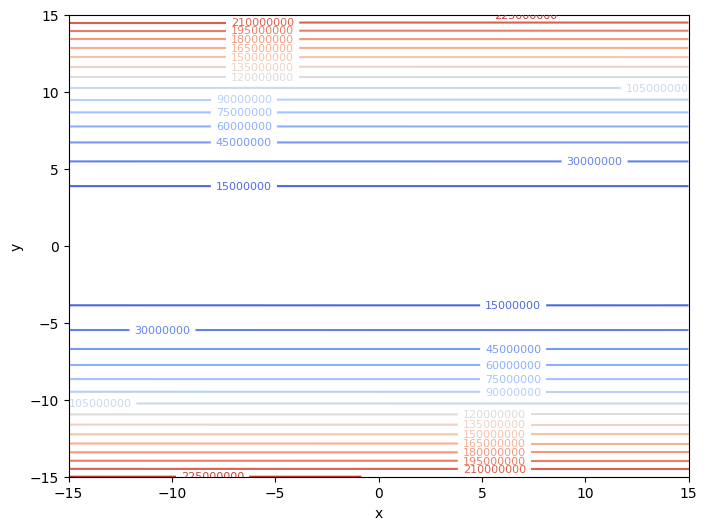

Computing for 15x^2 + 1000000y^2 - 7x + y - 8:
Found point:  [nan nan]
did not converge


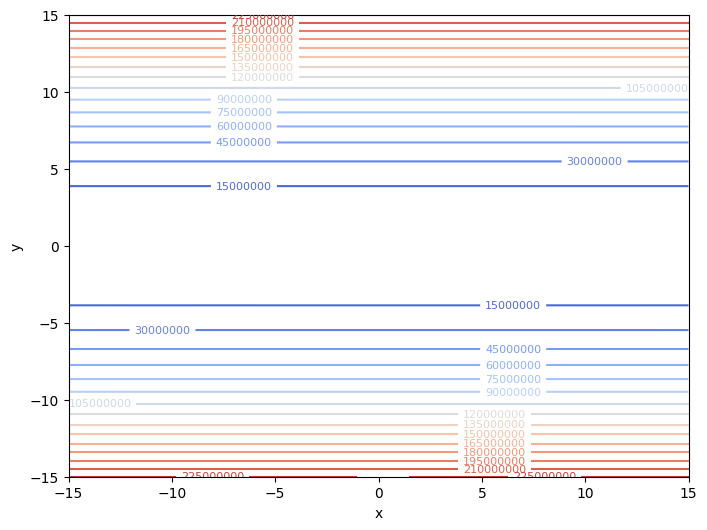

In [49]:
myGD.test_scaling('nesterov')

### Testing AdaGrad

Computing for 1000000x^2 + 2xy + 3y^2:
Found point:  [-2.18838083e-06  2.18838083e-06]
in 466 iterations


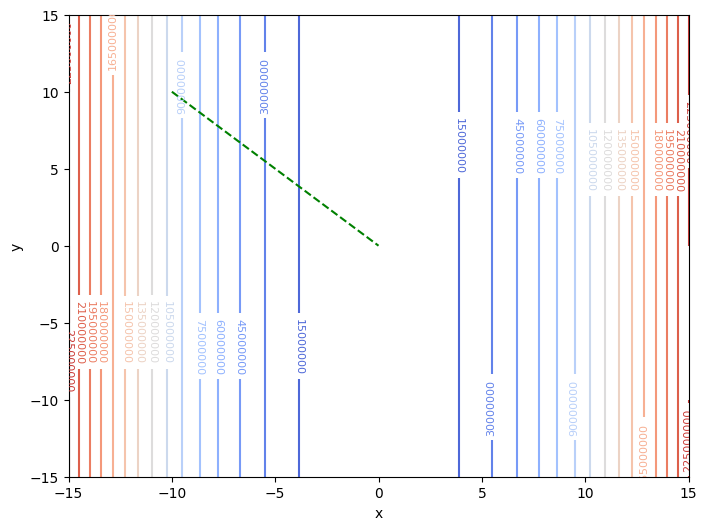

<ipython-input-42-680eb2dfd174>:196: VisibleDeprecationWarning: Creating an ndarray from ragged nested sequences (which is a list-or-tuple of lists-or-tuples-or ndarrays with different lengths or shapes) is deprecated. If you meant to do this, you must specify 'dtype=object' when creating the ndarray.
  table = np.append(table, np.array([name,


Computing for 1000000(x - 1)^2 + 3(y - 3)^2 + 4xy - 3:
Found point:  [0.99999119 2.33334113]
in 903 iterations


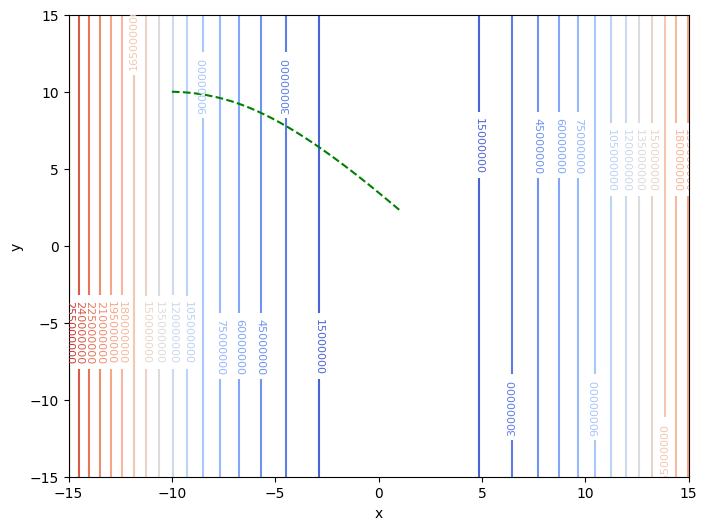

Computing for 35x^2 + 71xy + 1000000y^2 - 8x + 62y + 11:
Found point:  [-9.94370214e+00  3.22007755e-04]
did not converge


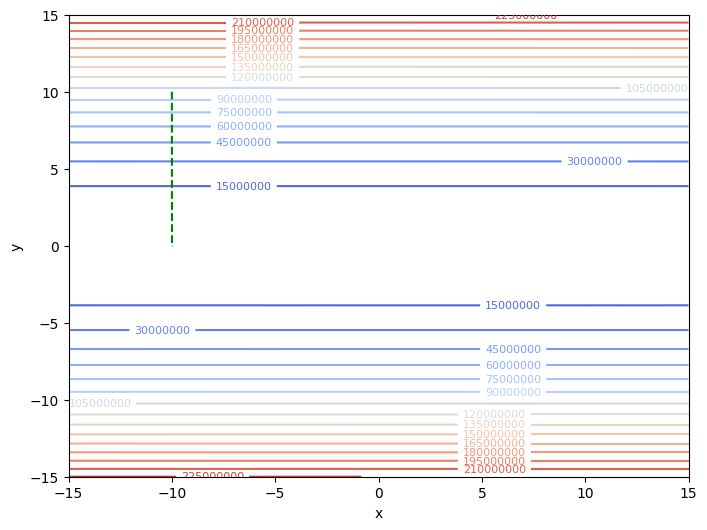

Computing for 15x^2 + 1000000y^2 - 7x + y - 8:
Found point:  [-9.97549075e+00 -5.00000000e-07]
did not converge


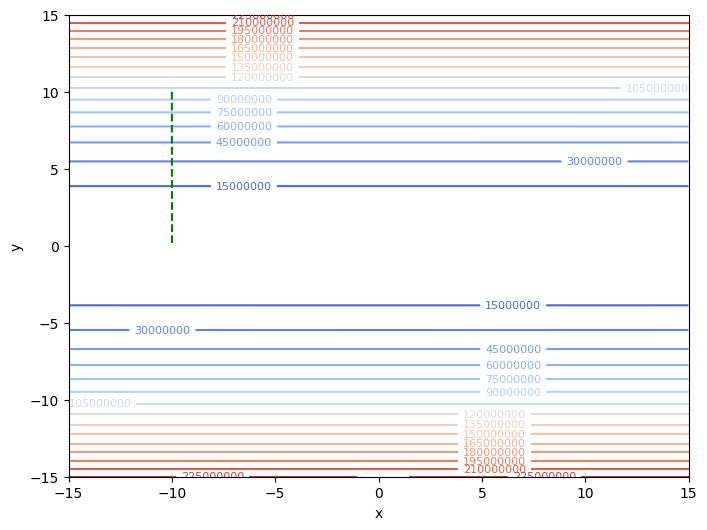

In [50]:
myGD.test_scaling('adagrad')

### Testing RMSprop

Computing for 1000000x^2 + 2xy + 3y^2:
Found point:  [-9.81910989e-08  9.81910994e-08]
in 27 iterations


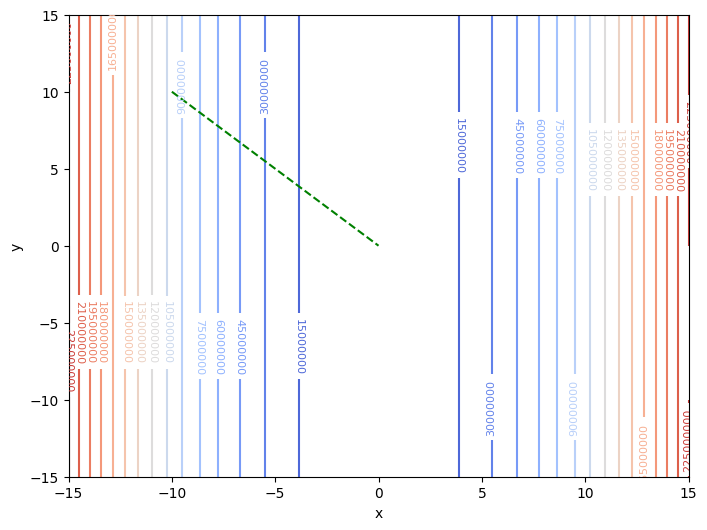

<ipython-input-42-680eb2dfd174>:196: VisibleDeprecationWarning: Creating an ndarray from ragged nested sequences (which is a list-or-tuple of lists-or-tuples-or ndarrays with different lengths or shapes) is deprecated. If you meant to do this, you must specify 'dtype=object' when creating the ndarray.
  table = np.append(table, np.array([name,


Computing for 1000000(x - 1)^2 + 3(y - 3)^2 + 4xy - 3:
Found point:  [0.99999514 2.33333343]
in 30 iterations


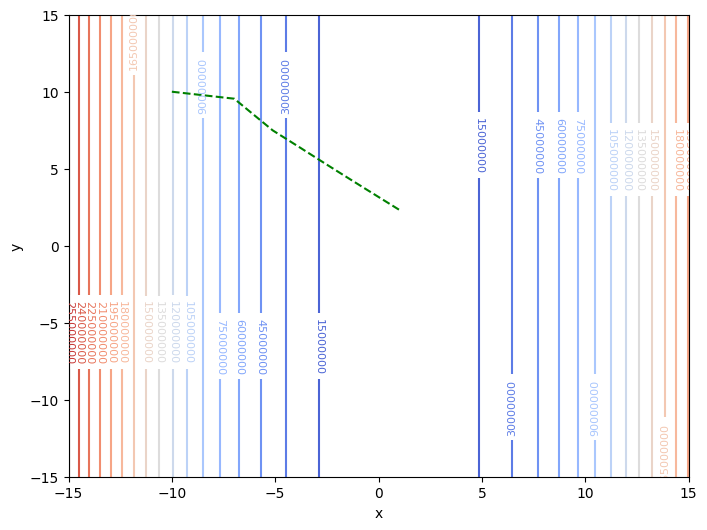

Computing for 35x^2 + 71xy + 1000000y^2 - 8x + 62y + 11:
Found point:  [0.61432127 0.49996494]
in 546 iterations


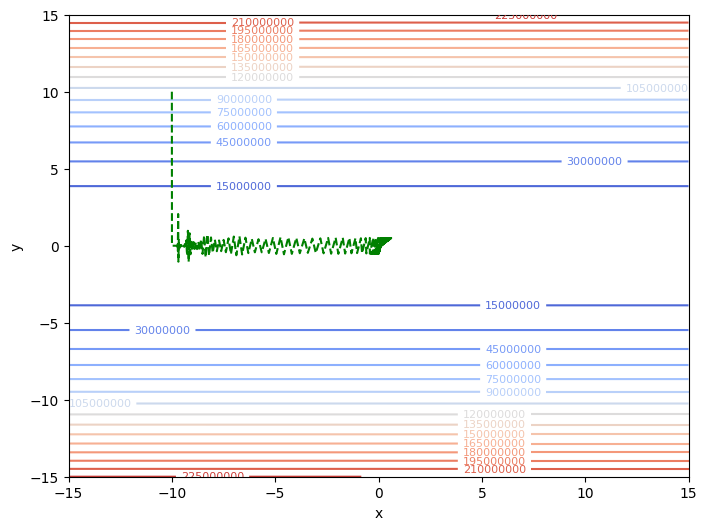

Computing for 15x^2 + 1000000y^2 - 7x + y - 8:
Found point:  [ 2.33317266e-01 -3.64641744e-07]
in 27 iterations


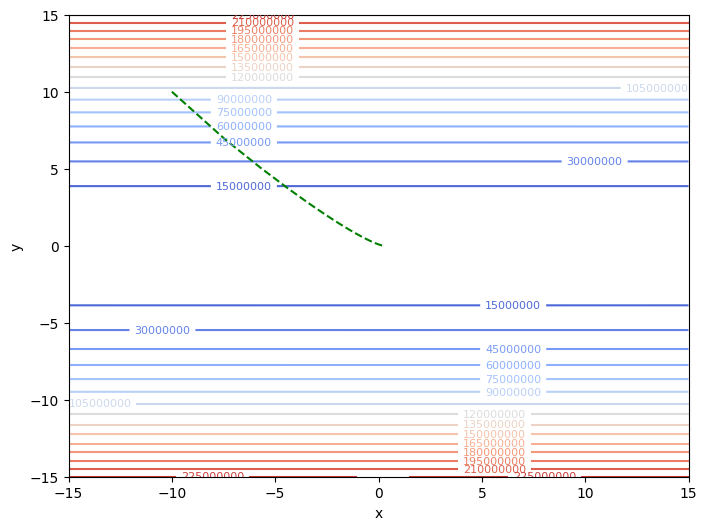

In [51]:
myGD.test_scaling('rmsprop')

### Testing Adam

Computing for 1000000x^2 + 2xy + 3y^2:
Found point:  [-2.18197195e-06  2.18197217e-06]
in 288 iterations


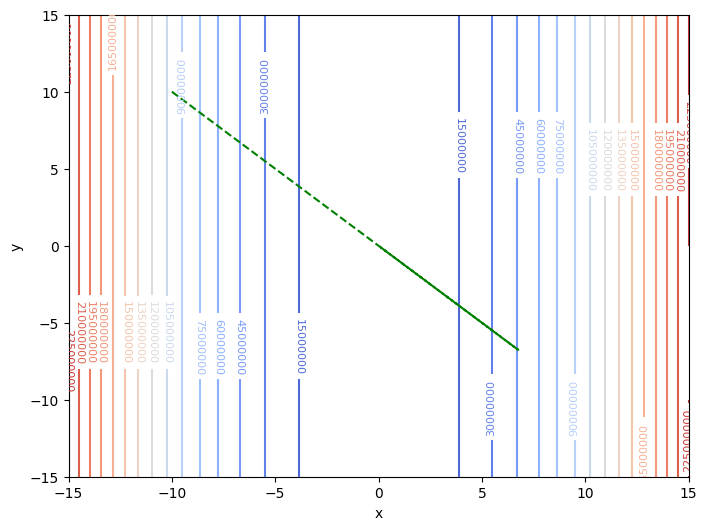

<ipython-input-42-680eb2dfd174>:196: VisibleDeprecationWarning: Creating an ndarray from ragged nested sequences (which is a list-or-tuple of lists-or-tuples-or ndarrays with different lengths or shapes) is deprecated. If you meant to do this, you must specify 'dtype=object' when creating the ndarray.
  table = np.append(table, np.array([name,


Computing for 1000000(x - 1)^2 + 3(y - 3)^2 + 4xy - 3:
Found point:  [0.99999562 2.3333092 ]
in 308 iterations


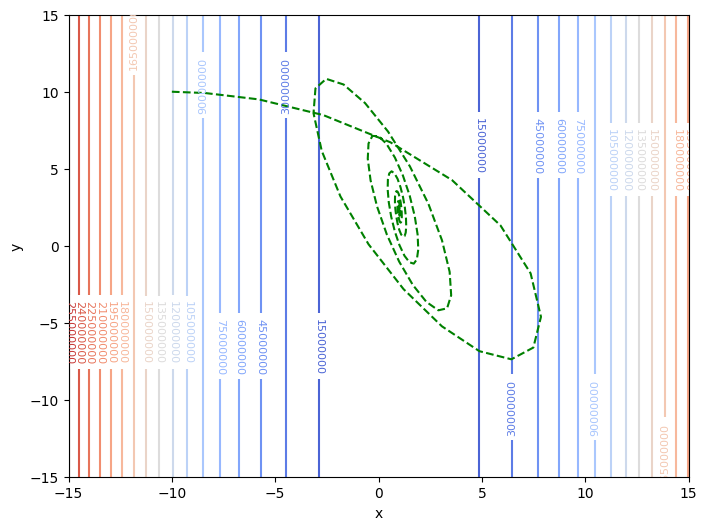

Computing for 35x^2 + 71xy + 1000000y^2 - 8x + 62y + 11:
Found point:  [ 1.13749198e-01 -3.50024345e-05]
in 9490 iterations


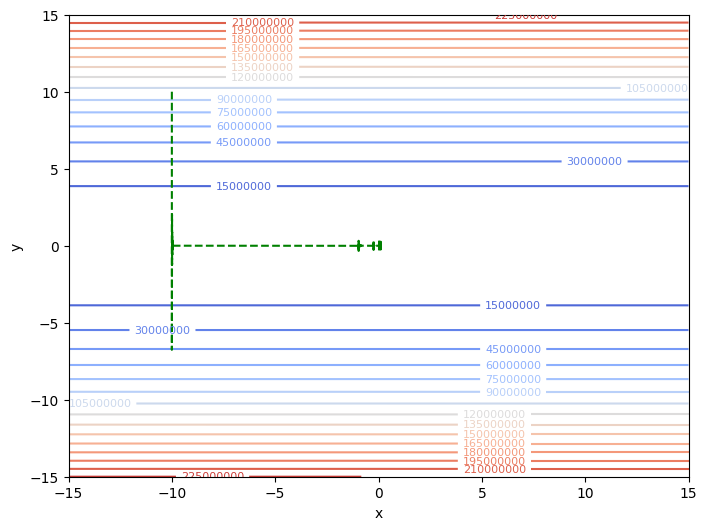

Computing for 15x^2 + 1000000y^2 - 7x + y - 8:
Found point:  [ 2.32651561e-01 -5.00000000e-07]
in 2345 iterations


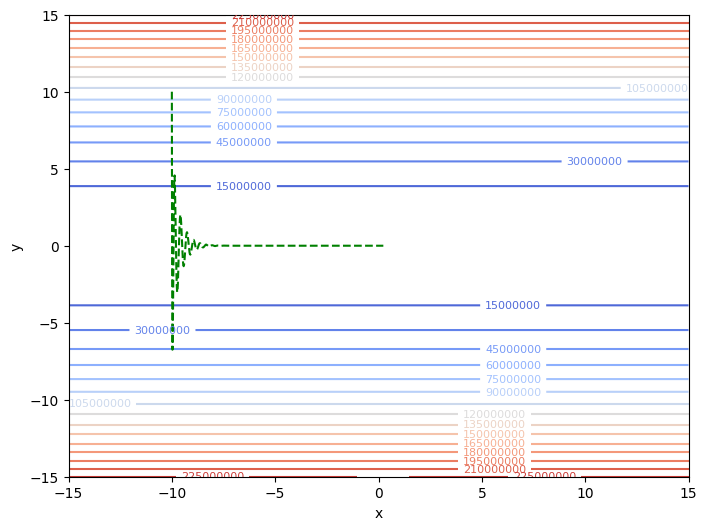

In [52]:
myGD.test_scaling('adam')